# Exp 14: the race between the inefficient and efficient matchings

Three instances where the road network departs from Prop 3 past saturation:

- **#5, #29** (exp_10 road / exp_11 star): a second inefficient regime just past `L` ends on the road network but persists with linear costs;
- **#11** (exp_12 road / exp_13 star): the first window exits at ε_h⁺ = 6.6 with linear costs, but only at 7.70 on the road network, past `L` = 7.

Each switch should be a race between two profits:

- **Π_I(ε_h)**: the best platform profit with all high types matched (inefficient);
- **Π_E(ε_h)**: the best platform profit with no high type matched (efficient).

The saved sweeps only give Π_I where the solver chose it, and give Π_E as `forced_lower_bound`, the profit of one tied min-cost set (a lower bound). exp_14 solves both exactly on a common ε_h grid in both arms, by restricting the search to the high types forced matched (Π_I) or forced unmatched (Π_E). Each solve also records every high type's η and the dual π of its stability constraint, so the slope dΠ/dε_h = Σ_high π·η can be checked against finite differences.

Grids: #5 5.0–5.6 (step 0.025), #29 6.0–6.6 (step 0.05), #11 6.4–8.0 (step 0.2; its road solves take about 17 minutes each).

## Summary of findings

All 188 forced solves are proved optimal (largest relative gap 4e-12). At every grid point shared with the saved sweeps (37 points), the better of Π_I and Π_E reproduces the sweep's optimum and picks the same matching, low types included. No partial matching is optimal at any of them, and Π_E equals the sweep's `forced_lower_bound`, so the saved efficient profits were already exact. Every crossing of Π_I and Π_E lands on the switch the sweep observed: inside its bracket, or within one grid step for #29's onset (6.1793 against (6.150, 6.175]).

**#5 and #29: the second inefficient regime ends because keeping the high type matched keeps getting more expensive, while pricing it out stops getting more expensive.**

| | Π_I slope (matched) | Π_E slope (unmatched) | crossings |
|---|---|---|---|
| #5 road | −52,997 per ton until 5.475, then 0 | about −200k until 5.24, then 0 | in at 5.1897, back out at 5.4095 |
| #5 star | 0 | about −240k until 5.24, then 0 | in at 5.2000 only |
| #29 road | −31k, then −14,863 per ton until 6.5 | −234k falling to 0 by 6.3 | in at 6.1793, back out at 6.4610 |
| #29 star | 0 from 6.05 | about −330k until 6.25, then 0 | in at 6.2401 only |

- **Up to the onset, the efficient side falls faster.** The gap opens and the platform switches to matching the high type.
- **Then the efficient side goes flat.** The unmatched high types' η falls to 0, so a bigger budget no longer costs anything to deter.
- **On the road network, the matched side keeps falling.** Its slope is η per ton (53.0k in #5; 14.9k in #29, from `competent_wing`), which is the swap effect, so the gap closes again.
- **With linear costs, the matched side is flat**, so the gap stays open.

**#11: the late exit is a bigger head start that closes slowly past saturation.** With linear costs, the three matched high types cost 800k per ton (3 × η = 266,667). That is faster than the efficient side (−481k to −402k), so the gap closes exactly at ε_h⁺ = 6.6. On the road network:
- **The head start is larger.** At 6.6, Π_I − Π_E = 207k against 0 in the star arm. This is the same routing advantage behind the early onsets.
- **Before L, the gap closes fast.** Π_I falls at −925k per ton against about −510k for Π_E.
- **At L the matched side slows.** One high type's η drops from 330k to 69k, so Π_I's slope falls to about −425k per ton.
- **Past L, pricing the high types out keeps getting more expensive too.** The unmatched high types' η stays positive through 8.0; in the star arm it is 0 from 7.2. Π_E's slope is about −410k to −190k per ton.
- **So past L the two sides fall at almost the same rate.** The inefficient side is only slightly steeper, so the remaining 29k gap at L takes until 7.70 to close.

**What the matched high type does with extra budget (#5, #29).** Past saturation its truck is full, so a bigger budget only lets its worst-case deviation swap its own farmers for outside ones. The deviation is reconstructed at every saved solve; its value reproduces the saved high-type profit to 1e-7, and its η matches the solve's everywhere except at ε_h = L, a kink where the two LPs return different one-sided slopes.
- **The test is a swap value.** At the solve's payments, take the deviation's full-truck route S and value replacing an own farmer f with an outside farmer g using whole-route costs: (margin_g − margin_f) − [c(S − f + g) − c(S)]. Past saturation, the best such swap is worth exactly η in every road row.
- **With linear costs, every swap is worth exactly 0.** A farmer's payment absorbs its own collection cost, which is the same for every collector, so all farmers are worth the same to the high type and η = 0.
- **On the road network, some swaps pay.**
  - #5: dropping `dreamy_hamilton_f1` for `wizardly_tharp_f0` gains 26,768 in margin and *lowers* the route cost by 26,229 (although `wizardly_tharp_f0`'s own trip costs 350,476): 52,997 per ton, which is η.
  - #29: `competent_wing`'s best swap is worth 14,863 = η. `zen_gauss` has no swap worth more than 0, so η = 0 and its profit stays flat.
  - The platform posts one payment per farmer, set against what it would cost the binding low type to take that farmer. A high type whose route already passes nearby adds the farmer for much less, so it keeps a margin the payment didn't price in.
- **Unmatched high types are priced out exactly.** Their worst-case deviation is worth exactly 0: the platform sets payments so that every candidate deviation route breaks even.

**The duals account for the slopes.** Where the slope barely changes across an interval, the finite-difference slope matches Σ_high π·η to within 3 IDR per ton on #5's fine grid and within 1.3% on #11's 0.2-wide road intervals. A matched high type always has π = −1. An unmatched one has π between about −0.97 and −1.56: pricing it out costs more or less than one-for-one, depending on which farmer payments have to move.

In [1]:
from pathlib import Path
import gzip
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter

In [2]:
RESULTS_14 = Path("../results/exp_14")
# saved sweeps the exp_14 instances come from
SAVED_SWEEPS = {
    5: {"road": Path("../results/exp_10"), "star": Path("../results/exp_11/star")},
    29: {"road": Path("../results/exp_10"), "star": Path("../results/exp_11/star")},
    11: {"road": Path("../results/exp_12"), "star": Path("../results/exp_13/star")},
}
SOURCE_LABELS = {5: ("exp_10", "exp_11"), 29: ("exp_10", "exp_11"), 11: ("exp_12", "exp_13")}
INSTANCES = [5, 29, 11]
FIG_DIR = Path("../figures/exp_14")
FIG_DIR.mkdir(parents=True, exist_ok=True)

ARMS = ["road", "star"]

# light-mode chart tokens (matches exp_11_results)
SURFACE, INK, INK_SECONDARY, INK_MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
ARM_COLORS = {"star": "#eb6834", "road": "#1baf7a"}
EFFICIENT_COLOR = "#898781"
SHADE = "#ecebe7"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK_SECONDARY, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "xtick.color": INK_MUTED, "ytick.color": INK_MUTED,
    "xtick.labelcolor": INK_SECONDARY, "ytick.labelcolor": INK_SECONDARY,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GRID, "grid.linewidth": 0.8, "legend.frameon": False,
})
# thousands, keeping one decimal only when it is not a whole number of thousands (2.5k, not 2k)
thousands = FuncFormatter(lambda x, _: f"{x / 1e3:,.1f}".rstrip("0").rstrip(".") + "k")

## Load

In [3]:
rows, grids, files = [], {}, sorted(RESULTS_14.glob("instance_*_*_*.json.gz"))
for file in files:
    with gzip.open(file, "rt", encoding="utf-8") as f:
        payload = json.load(f)
    i = payload["instance_id"]
    grids[i] = payload["eps_h_grid"]
    for run in payload["runs"]:
        primary = run["summary"]["platform_solve_result"]["primary_result"]
        high = run["high_ids"]
        matched = set(primary["selected_intermediaries"])
        rows.append({
            "instance": i, "arm": run["arm"], "side": run["side"], "eps_h": run["eps_h"],
            "profit": primary["platform_profit"],
            "matched": tuple(sorted(matched)), "high_ids": tuple(sorted(high)),
            "n_high_matched": len(matched & set(high)), "T_h": len(high),
            "envelope_slope": sum(primary["stability_duals"][h] * primary["eta"][h] for h in high),
            "max_eta_h": max(primary["eta"][h] for h in high),
            "duals_h": tuple(round(primary["stability_duals"][h], 4) for h in high),
            "rel_gap": run["summary"]["rel_gap"], "wall_time": run["wall_time"],
        })
runs = pd.DataFrame(rows).sort_values(["instance", "arm", "side", "eps_h"]).reset_index(drop=True)

# the forcing must hold: all high types matched on the inefficient side, none on the efficient side
expected = np.where(runs["side"] == "inefficient", runs["T_h"], 0)
assert (runs["n_high_matched"] == expected).all()

status = runs.groupby(["instance", "arm", "side"]).agg(solved=("eps_h", "size"), hours=("wall_time", lambda t: t.sum() / 3600))
status["grid"] = [len(grids[i]) for i, _, _ in status.index]
status["complete"] = status["solved"] == status["grid"]
print(f"{len(runs)} solves; max rel_gap {runs['rel_gap'].max():.1e}")
status.round(2)

188 solves; max rel_gap 3.9e-12


solved  hours  grid  complete
instance arm  side                                      
5        road efficient        25   0.00    25      True
              inefficient      25   0.00    25      True
         star efficient        25   0.00    25      True
              inefficient      25   0.00    25      True
11       road efficient         9   0.26     9      True
              inefficient       9   0.32     9      True
         star efficient         9   0.08     9      True
              inefficient       9   0.12     9      True
29       road efficient        13   0.12    13      True
              inefficient      13   0.16    13      True
         star efficient        13   0.05    13      True
              inefficient      13   0.06    13      True

### Consistency with the saved sweeps

First, every exp_14 run must have the same high-type intermediaries as the saved sweep (the instance was rebuilt identically). Then, at grid points that coincide with a point of the saved sweep, max(Π_I, Π_E) must equal the sweep's optimum, unless a *partial* matching (some but not all high types) is optimal there, which neither forced side covers. Π_E must also be at least the sweep's `forced_lower_bound`; where the two are equal, the tied min-cost set the sweep saved was already the best efficient set.

In [4]:
saved_rows = []
for i, sources in SAVED_SWEEPS.items():
    for arm, root in sources.items():
        for file in sorted(root.rglob("*.json.gz")):
            with gzip.open(file, "rt", encoding="utf-8") as f:
                sweep = json.load(f)
            if sweep["instance_id"] != i:
                continue
            high_ids = set(sweep["high_ids"])
            # exp_14 must rebuild the same instance: the same high-type intermediaries as the sweep
            exp14_high = {frozenset(h) for h in runs.query("instance == @i and arm == @arm")["high_ids"]}
            assert exp14_high <= {frozenset(high_ids)}, f"#{i} {arm}: exp_14 high types differ from the saved sweep's"
            for run in sweep["runs"]:
                primary = run["summary"]["platform_solve_result"]["primary_result"]
                saved_rows.append({
                    "instance": i, "arm": arm, "eps_h": round(run["eps_h"], 6),
                    "saved_optimal": primary["platform_profit"],
                    "saved_n_high": len(high_ids & set(primary["selected_intermediaries"])), "T_h": len(high_ids),
                    "saved_forced_lower_bound": run["summary"]["forced_lower_bound"],
                })
saved = pd.DataFrame(saved_rows).sort_values(["instance", "arm", "eps_h"]).reset_index(drop=True)

wide = runs.pivot_table(index=["instance", "arm", "eps_h"], columns="side", values="profit").reset_index()
wide.columns.name = None
wide = wide.rename(columns={"inefficient": "Pi_I", "efficient": "Pi_E"}).dropna(subset=["Pi_I", "Pi_E"])
wide["gap"] = wide["Pi_I"] - wide["Pi_E"]

common = wide.assign(eps_h=wide["eps_h"].round(6)).merge(saved, on=["instance", "arm", "eps_h"])
common["best"] = common[["Pi_I", "Pi_E"]].max(axis=1)
common["partial_optimal"] = (common["saved_n_high"] > 0) & (common["saved_n_high"] < common["T_h"])
common["optimal_matches"] = np.isclose(common["best"], common["saved_optimal"], rtol=1e-6, atol=1.0)
common["choice_matches"] = (common["gap"] > 0) == (common["saved_n_high"] > 0)
common["Pi_E_minus_saved_lb"] = common["Pi_E"] - common["saved_forced_lower_bound"]
display(common.groupby(["instance", "arm"]).agg(
    points=("eps_h", "size"), partial_optimal=("partial_optimal", "sum"),
    optimum_reproduced=("optimal_matches", "mean"), same_choice=("choice_matches", "mean"),
    Pi_E_minus_saved_lb_min=("Pi_E_minus_saved_lb", "min"), Pi_E_minus_saved_lb_max=("Pi_E_minus_saved_lb", "max"),
).round(2))
print("points where the optimum is not reproduced:")
common.loc[~common["optimal_matches"], ["instance", "arm", "eps_h", "Pi_I", "Pi_E", "saved_optimal", "saved_n_high", "T_h"]].round(
    {"Pi_I": 0, "Pi_E": 0, "saved_optimal": 0})

points  partial_optimal  optimum_reproduced  same_choice  \
instance arm                                                              
5        road       8                0                 1.0          1.0   
         star       6                0                 1.0          1.0   
11       road       6                0                 1.0          1.0   
         star       6                0                 1.0          1.0   
29       road       6                0                 1.0          1.0   
         star       5                0                 1.0          1.0   

               Pi_E_minus_saved_lb_min  Pi_E_minus_saved_lb_max  
instance arm                                                     
5        road                     -0.0                      0.0  
         star                      0.0                      0.0  
11       road                     -0.0                      0.0  
         star                     -0.0                      0.0  
29       road                     -0.0                      0.0  
         star                     -0.0                      0.0

points where the optimum is not reproduced:


,instance,arm,eps_h,Pi_I,Pi_E,saved_optimal,saved_n_high,T_h


## The race

`gap` = Π_I − Π_E: positive where matching the high types beats the efficient set. Each crossing is located by linear interpolation between grid points and compared with the nearest switch the saved sweep observed (the matched high-type count changing from or to zero). `distance` is how far outside that bracket the interpolated crossing lies; on the coarser grids (#29: 0.05, #11: 0.2) the gap can bend between grid points, so a crossing within one grid step counts as `consistent`.

In [5]:
def crossings(g):
    eps, gap = g["eps_h"].to_numpy(), g["gap"].to_numpy()
    out = []
    for k in np.flatnonzero(np.sign(gap[:-1]) != np.sign(gap[1:])):
        x = eps[k] - gap[k] * (eps[k + 1] - eps[k]) / (gap[k + 1] - gap[k])
        out.append({"direction": "into inefficient" if gap[k + 1] > gap[k] else "back to efficient", "crossing": x})
    return out


def observed_switches(i, arm, lo, hi):
    s = saved.query("instance == @i and arm == @arm").reset_index(drop=True)
    on = s["saved_n_high"] > 0
    return [(s.eps_h[k - 1], s.eps_h[k]) for k in range(1, len(s))
            if on[k] != on[k - 1] and s.eps_h[k] >= lo and s.eps_h[k - 1] <= hi]


cross_rows = []
for (i, arm), g in wide.groupby(["instance", "arm"]):
    observed = observed_switches(i, arm, g.eps_h.min(), g.eps_h.max())
    step = float(np.diff(g["eps_h"]).min())
    found = crossings(g)
    for c in found:
        dist = [0.0 if o[0] - 1e-9 <= c["crossing"] <= o[1] + 1e-9 else min(abs(c["crossing"] - o[0]), abs(c["crossing"] - o[1]))
                for o in observed]
        k = int(np.argmin(dist)) if dist else None
        cross_rows.append({"instance": i, "arm": arm, "direction": c["direction"], "crossing": c["crossing"],
                           "observed_switch": f"({observed[k][0]:.4f}, {observed[k][1]:.4f}]" if k is not None else "none",
                           "distance": dist[k] if k is not None else np.nan, "grid_step": step,
                           "consistent": k is not None and dist[k] <= step})
cross = pd.DataFrame(cross_rows)
unmatched_observed = [(i, arm, o) for (i, arm), g in wide.groupby(["instance", "arm"])
                      for o in observed_switches(i, arm, g.eps_h.min(), g.eps_h.max())
                      if not any(abs(r.crossing - o[0]) <= r.grid_step + 1e-9 or abs(r.crossing - o[1]) <= r.grid_step + 1e-9
                                 for r in cross.query("instance == @i and arm == @arm").itertuples())]
print(f"observed switches without a crossing within one grid step: {unmatched_observed or 'none'}")
cross = pd.DataFrame(cross_rows)
cross.round(4)

observed switches without a crossing within one grid step: none


,instance,arm,direction,crossing,observed_switch,distance,grid_step,consistent
0,5,road,into inefficient,5.1897,"(5.1875, 5.2000]",0.0000,0.025,True
1,5,road,back to efficient,5.4095,"(5.4062, 5.4250]",0.0000,0.025,True
2,5,star,into inefficient,5.2000,"(5.2000, 5.2188]",0.0000,0.025,True
3,11,road,back to efficient,7.6988,"(7.6875, 7.7031]",0.0000,0.200,True
4,11,star,back to efficient,6.6000,"(6.5750, 6.6000]",0.0000,0.200,True
5,29,road,into inefficient,6.1793,"(6.1500, 6.1750]",0.0043,0.050,True
6,29,road,back to efficient,6.4610,"(6.4437, 6.4625]",0.0000,0.050,True
7,29,star,into inefficient,6.2401,"(6.2375, 6.2562]",0.0000,0.050,True


## Why each side moves: envelope slopes

dΠ/dε_h = Σ_high π·η, where π is the dual of a high type's stability constraint: π = −1 for a matched high type, which is paid its deviation profit directly, and |π| > 1 for an unmatched one, which must instead be priced out through farmer payments. The table lists each side's slope range on stretches with the same regime (some high type has η > 0, or none). Below it, each finite difference between neighbouring grid points is compared with the envelope slope, on intervals where that slope is nearly the same at both ends (within 5%) and the matched set does not change; elsewhere the profit bends inside the interval, which is common on the road network, where the high types' η changes in small steps.

In [6]:
seg_rows, fd_rows = [], []
for (i, arm, side), g in runs.groupby(["instance", "arm", "side"]):
    g = g.reset_index(drop=True)
    regime = (g["max_eta_h"] > 0.5).astype(int)
    for _, seg in g.groupby((regime != regime.shift()).cumsum()):
        seg_rows.append({"instance": i, "arm": arm, "side": side, "eps_from": seg.eps_h.min(), "eps_to": seg.eps_h.max(),
                         "points": len(seg), "max_eta_h": f"{seg.max_eta_h.min():,.0f} – {seg.max_eta_h.max():,.0f}",
                         "envelope_slope_per_ton": f"{seg.envelope_slope.min():,.0f} – {seg.envelope_slope.max():,.0f}"})
    for k in range(len(g) - 1):
        a, b = g.iloc[k], g.iloc[k + 1]
        fd_rows.append({"instance": i, "arm": arm, "side": side, "eps_mid": (a.eps_h + b.eps_h) / 2,
                        "finite_difference": (b.profit - a.profit) / (b.eps_h - a.eps_h),
                        "envelope_mean": (a.envelope_slope + b.envelope_slope) / 2,
                        # compare only where the slope barely changes between the ends (no kink inside the interval)
                        "kink": a.matched != b.matched or not np.isclose(a.envelope_slope, b.envelope_slope, rtol=0.05, atol=1.0)})
display(pd.DataFrame(seg_rows))
fd = pd.DataFrame(fd_rows)
fd["abs_diff"] = (fd["finite_difference"] - fd["envelope_mean"]).abs()
fd["rel_diff"] = fd["abs_diff"] / fd["finite_difference"].abs().clip(lower=1.0)
fd.query("not kink").groupby(["instance", "arm", "side"]).agg(
    intervals=("abs_diff", "size"), max_abs_diff=("abs_diff", "max"), max_rel_diff=("rel_diff", "max"),
    max_abs_slope=("finite_difference", lambda s: s.abs().max()),
).round({"max_abs_diff": 1, "max_rel_diff": 4, "max_abs_slope": 0})

,instance,arm,side,eps_from,eps_to,points,max_eta_h,envelope_slope_per_ton
0,5,road,efficient,5.00,5.225,10,"167,881 – 175,435","-210,523 – -192,782"
1,5,road,efficient,5.25,5.600,15,0 – 0,0 – 0
2,5,road,inefficient,5.00,5.475,20,"52,997 – 52,997","-52,997 – -52,997"
3,5,road,inefficient,5.50,5.600,5,0 – 0,0 – 0
4,5,star,efficient,5.00,5.225,10,"199,043 – 208,000","-249,600 – -228,566"
5,5,star,efficient,5.25,5.600,15,0 – 0,0 – 0
6,5,star,inefficient,5.00,5.600,25,-0 – 0,0 – 0
7,11,road,efficient,6.40,8.000,9,"80,166 – 148,745","-542,149 – -190,371"
8,11,road,inefficient,6.40,8.000,9,"172,447 – 329,987","-925,074 – -304,253"
9,11,star,efficient,6.40,7.000,4,"128,000 – 140,000","-481,250 – -402,286"


intervals  max_abs_diff  max_rel_diff  \
instance arm  side                                                 
5        road efficient           23           2.6        0.0000   
              inefficient         23           0.0        0.0000   
         star efficient           23           3.1        0.0000   
              inefficient         24           0.0        0.0000   
11       road inefficient          5        4091.2        0.0133   
         star efficient            4           0.0        0.0000   
              inefficient          7           0.0        0.0000   
29       road efficient            6           0.0        0.0000   
              inefficient         10           0.0        0.0000   
         star efficient           11          11.8        0.0000   
              inefficient         11           0.0        0.0000   

                           max_abs_slope  
instance arm  side                        
5        road efficient         209475.0  
              inefficient        52997.0  
         star efficient         248358.0  
              inefficient            0.0  
11       road inefficient       925074.0  
         star efficient              0.0  
              inefficient       800000.0  
29       road efficient              0.0  
              inefficient        14863.0  
         star efficient         343802.0  
              inefficient            0.0

## Figure: efficient vs. inefficient profit

One row per instance, one column per arm; each panel has its own y-scale. Π_I is the profit with all high types matched and Π_E the profit with none; shading marks where matching the high types is optimal (Π_I > Π_E, between the interpolated crossings). Dashed lines are the crossings, and the solid line is `L`.

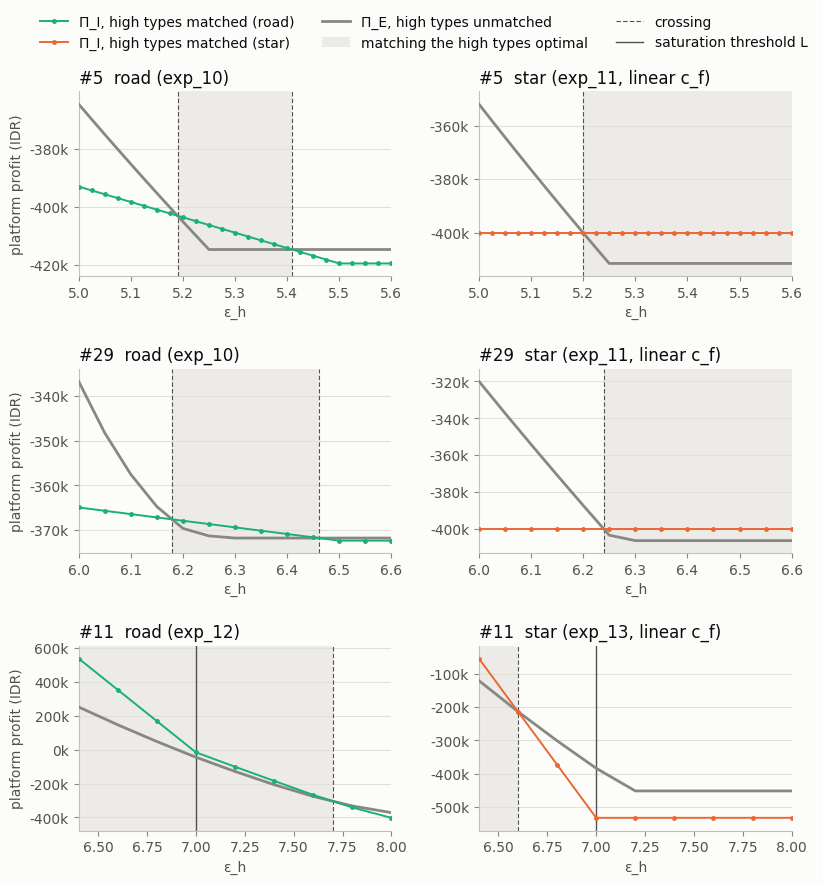

In [7]:
# L from each instance's window, as saved by its source sweep
L_of = {}
for i, sources in SAVED_SWEEPS.items():
    for file in sorted(sources["star"].rglob("*.json.gz")):
        with gzip.open(file, "rt", encoding="utf-8") as f:
            sweep = json.load(f)
        if sweep["instance_id"] == i:
            w = sweep["window"]
            L_of[i] = float(w["K"]) - float(w["n_h"])
            break

present = [i for i in INSTANCES if i in set(wide["instance"])]
def fit_ylim(ax, values, pad=0.08):
    lo, hi = np.nanmin(values), np.nanmax(values)
    span = hi - lo if hi > lo else max(1.0, abs(hi))
    ax.set_ylim(lo - pad * span, hi + pad * span)


def draw_panel(ax, i, arm, w, x_lo, x_hi):
    eps = w["eps_h"].to_numpy()
    found = sorted(cross.query("instance == @i and arm == @arm")["crossing"].dropna())
    bounds = [eps.min(), *found, eps.max()]
    for x0, x1 in zip(bounds[:-1], bounds[1:]):
        if np.interp((x0 + x1) / 2, eps, w["gap"].to_numpy()) > 0:
            ax.axvspan(x0, x1, color=SHADE, linewidth=0, zorder=0)
    for x in found:
        ax.axvline(x, color=INK_SECONDARY, linewidth=0.8, linestyle=(0, (4, 2)), zorder=1)
    if eps.min() < L_of[i] < eps.max():
        ax.axvline(L_of[i], color=INK_SECONDARY, linewidth=1.0, zorder=1)
    ax.plot(eps, w["Pi_E"], color=EFFICIENT_COLOR, linewidth=2, zorder=3)
    ax.plot(eps, w["Pi_I"], color=ARM_COLORS[arm], linewidth=1.4, marker="o", markersize=2.5, zorder=4)
    ax.set_xlim(x_lo, x_hi)
    # fit the y-range to what is visible in this window
    visible = w[(w["eps_h"] >= x_lo - 1e-9) & (w["eps_h"] <= x_hi + 1e-9)]
    fit_ylim(ax, np.concatenate([visible["Pi_I"], visible["Pi_E"]]))
    ax.yaxis.set_major_formatter(thousands)
    ax.grid(axis="y")
    ax.set_axisbelow(True)


fig, axes = plt.subplots(len(present), 2, figsize=(9.2, 3.2 * len(present)), squeeze=False,
                         gridspec_kw={"hspace": 0.5, "wspace": 0.28})
for row, i in enumerate(present):
    for col, arm in enumerate(ARMS):
        ax = axes[row, col]
        w = wide.query("instance == @i and arm == @arm")
        if w.empty:
            ax.set_visible(False)
            continue
        draw_panel(ax, i, arm, w, w["eps_h"].min(), w["eps_h"].max())
        road_src, star_src = SOURCE_LABELS[i]
        ax.set_title(f"#{i}  {'road (' + road_src + ')' if arm == 'road' else 'star (' + star_src + ', linear c_f)'}",
                     loc="left", color=INK)
        ax.set_xlabel("ε_h")
    axes[row, 0].set_ylabel("platform profit (IDR)")

fig.legend(handles=[
    Line2D([], [], color=ARM_COLORS["road"], marker="o", markersize=2.5, linewidth=1.4, label="Π_I, high types matched (road)"),
    Line2D([], [], color=ARM_COLORS["star"], marker="o", markersize=2.5, linewidth=1.4, label="Π_I, high types matched (star)"),
    Line2D([], [], color=EFFICIENT_COLOR, linewidth=2, label="Π_E, high types unmatched"),
    Patch(facecolor=SHADE, label="matching the high types optimal"),
    Line2D([], [], color=INK_SECONDARY, linewidth=0.8, linestyle=(0, (4, 2)), label="crossing"),
    Line2D([], [], color=INK_SECONDARY, linewidth=1.0, label="saturation threshold L"),
], loc="lower center", bbox_to_anchor=(0.5, 0.91 if len(present) > 1 else 0.98), ncol=3)
plt.savefig(FIG_DIR / "race_profits.png", bbox_inches="tight", dpi=300)
plt.show()

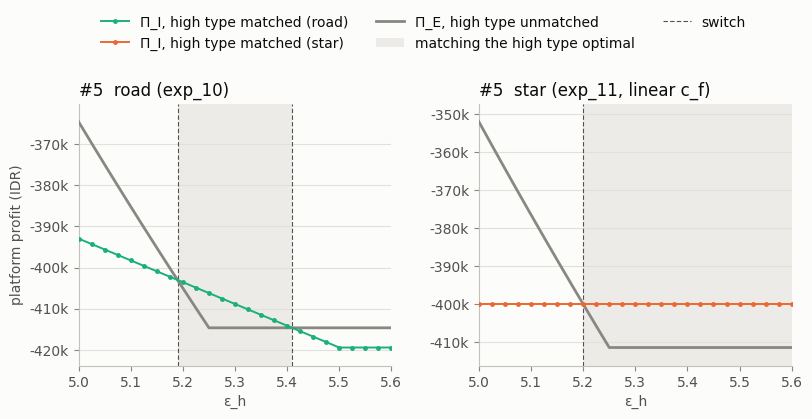

In [8]:
# Π_I vs. Π_E for instance #5 alone (same panels as the figure above)
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.4), squeeze=False, gridspec_kw={"wspace": 0.28})
for col, arm in enumerate(ARMS):
    ax = axes[0, col]
    w = wide.query("instance == 5 and arm == @arm")
    draw_panel(ax, 5, arm, w, w["eps_h"].min(), w["eps_h"].max())
    road_src, star_src = SOURCE_LABELS[5]
    ax.set_title(f"#5  {'road (' + road_src + ')' if arm == 'road' else 'star (' + star_src + ', linear c_f)'}",
                 loc="left", color=INK)
    ax.set_xlabel("ε_h")
axes[0, 0].set_ylabel("platform profit (IDR)")
fig.legend(handles=[
    Line2D([], [], color=ARM_COLORS["road"], marker="o", markersize=2.5, linewidth=1.4, label="Π_I, high type matched (road)"),
    Line2D([], [], color=ARM_COLORS["star"], marker="o", markersize=2.5, linewidth=1.4, label="Π_I, high type matched (star)"),
    Line2D([], [], color=EFFICIENT_COLOR, linewidth=2, label="Π_E, high type unmatched"),
    Patch(facecolor=SHADE, label="matching the high type optimal"),
    Line2D([], [], color=INK_SECONDARY, linewidth=0.8, linestyle=(0, (4, 2)), label="switch"),
], loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3)
plt.savefig(FIG_DIR / "race_profits_5.png", bbox_inches="tight", dpi=300)
plt.show()


In [9]:
dev_rows = []
for i in [5, 29]:
    path = RESULTS_14 / f"deviations_{i}.json"
    if not path.exists():
        continue
    for r in json.loads(path.read_text())["rows"]:
        farmers = {}
        for route in sorted(r["routes"], key=lambda rt: -rt["weight"]):   # each farmer as it appears on its heaviest route
            for f in route["farmers"]:
                farmers.setdefault(f["id"], f)
        dev_rows.append({
            "instance": i, "arm": r["arm"], "side": r["side"], "eps_h": r["eps_h"], "high_type": r["high_type"],
            "matched": r["matched"], "deviation_profit": r["deviation_profit"], "saved_profit": r["saved_profit"],
            "eta": r["eta"], "saved_eta": r["saved_eta"], "n_routes": len(r["routes"]),
            "farmers": farmers, "routes": r["routes"],
        })
dev = pd.DataFrame(dev_rows)
L_dev = dev["instance"].map(L_of)
matched = dev[dev["matched"]]
print(f"{len(dev)} deviations; matched high types: |deviation profit − saved profit| ≤ "
      f"{(matched['deviation_profit'] - matched['saved_profit']).abs().max():.1e}; unmatched: deviation profit in "
      f"[{dev.loc[~dev['matched'], 'deviation_profit'].min():.1f}, {dev.loc[~dev['matched'], 'deviation_profit'].max():.1f}] (priced out exactly)")
off = dev[(dev["eta"] - dev["saved_eta"]).abs() > 1.0]
print(f"η from the deviation vs. the solve's saved η: equal except at {len(off)} points, all at ε_h = L "
      f"({sorted(set(zip(off['instance'], off['eps_h'])))}), where the deviation value has a kink (below L budget fills the "
      "truck, above L it can only swap) and the two LPs report different one-sided slopes")

# swap values (exp_14_swaps.py): at the solve's payments, every one-for-one swap of an own farmer f on the deviation's base
# route S (full truck, most own farmers) for an outside farmer g not on S, valued with whole-route costs:
#   swap value = (margin_g − margin_f) − [c(S − f + g) − c(S)]
swap_rows, swap_sets = [], {}
for i in [5, 29]:
    path = RESULTS_14 / f"swaps_{i}.json"
    if not path.exists():
        continue
    for r in json.loads(path.read_text())["rows"]:
        key = (i, r["arm"], round(r["eps_h"], 6), r["high_type"])
        swap_sets[key] = pd.DataFrame(r["swaps"])
        best = max(r["swaps"], key=lambda x: x["swap_value"]) if r["swaps"] else None
        swap_rows.append({
            "instance": i, "arm": r["arm"], "eps_h": r["eps_h"], "high_type": r["high_type"], "eta": r["eta"],
            "base route (own+out)": f"{r['base_own']:g}+{r['base_out']:g}", "swaps": len(r["swaps"]),
            "best swap value": best["swap_value"] if best else np.nan,
            "best swap": f"{best['drop']} → {best['add']}" if best else "",
            "positive swaps": sum(x["swap_value"] > 1.0 for x in r["swaps"]),
            "worst swap value": min(x["swap_value"] for x in r["swaps"]) if r["swaps"] else np.nan,
        })
swaps = pd.DataFrame(swap_rows)
past_L = swaps[swaps["eps_h"] > swaps["instance"].map(L_of) + 1e-9]
print(f"swap values: {len(swaps)} base routes; past L, best single swap value − η in "
      f"[{(past_L['best swap value'] - past_L['eta']).min():,.1f}, {(past_L['best swap value'] - past_L['eta']).max():,.1f}]")

204 deviations; matched high types: |deviation profit − saved profit| ≤ 9.8e-08; unmatched: deviation profit in [-0.0, 0.0] (priced out exactly)
η from the deviation vs. the solve's saved η: equal except at 5 points, all at ε_h = L ([(5, 5.0), (29, 6.0)]), where the deviation value has a kink (below L budget fills the truck, above L it can only swap) and the two LPs report different one-sided slopes
swap values: 102 base routes; past L, best single swap value − η in [-0.0, 0.0]


In [10]:
# Past saturation, for each matched high type: what its best one-for-one swap is worth (whole-route costs), and η.
# With linear (star) costs every swap is worth exactly 0; on the road network the best swap is worth exactly η.
def fmt_range(lo, hi):
    return "" if np.isnan(lo) else (f"{lo:,.0f}" if abs(hi - lo) < 1 else f"{lo:,.0f} – {hi:,.0f}")


summary_rows = []
for (i, arm, h), g in past_L.groupby(["instance", "arm", "high_type"]):
    g = g.sort_values("eps_h")
    summary_rows.append({
        "instance": i, "arm": arm, "high_type": h, "ε_h": f"{g.eps_h.min():g} – {g.eps_h.max():g}",
        "best swap value": fmt_range(g["best swap value"].min(), g["best swap value"].max()),
        "η": fmt_range(g.eta.min(), g.eta.max()),
        "max |best swap − η|": (g["best swap value"] - g["eta"]).abs().max(),
        "positive swaps per point": fmt_range(g["positive swaps"].min(), g["positive swaps"].max()),
        "swaps per point": int(g["swaps"].max()),
    })
pd.DataFrame(summary_rows).round(1)

,instance,arm,high_type,ε_h,best swap value,η,max |best swap − η|,positive swaps per point,swaps per point
0,5,road,dreamy_hamilton,5.025 – 5.6,"0 – 52,997","0 – 52,997",0.0,0 – 2,2
1,5,star,dreamy_hamilton,5.025 – 5.6,-0,0,0.0,0,2
2,29,road,competent_wing,6.05 – 6.6,"-0 – 14,863","0 – 14,863",0.0,0 – 12,98
3,29,road,zen_gauss,6.05 – 6.6,-0,-0,0.0,0,98
4,29,star,competent_wing,6.05 – 6.6,0,0,0.0,0,98
5,29,star,zen_gauss,6.05 – 6.6,0,0,0.0,0,98


In [11]:
SWAP_POINTS = [(5, "dreamy_hamilton", 5.35), (29, "competent_wing", 6.35), (29, "zen_gauss", 6.35)]


def swap(row):
    routes = sorted(row["routes"], key=lambda rt: rt["out"])
    A, B = routes[0], routes[-1]
    a_ids, b_ids = {f["id"] for f in A["farmers"]}, {f["id"] for f in B["farmers"]}
    dropped = [f for f in A["farmers"] if f["id"] not in b_ids]
    added = [f for f in B["farmers"] if f["id"] not in a_ids]
    return A, B, dropped, added


for i, h, e in SWAP_POINTS:
    for arm in ARMS:
        r = dev.query("instance == @i and arm == @arm and side == 'inefficient' and high_type == @h and abs(eps_h - @e) < 1e-9")
        if r.empty:
            continue
        r = r.iloc[0]
        A, B, dropped, added = swap(r)
        print(f"#{i} {arm}, {h}, ε_h = {e}: η = {r['eta']:,.0f}; routes A = {A['own']:g} own + {A['out']:g} out "
              f"(weight {A['weight']:.2f}), B = {B['own']:g} own + {B['out']:g} out (weight {B['weight']:.2f})")
        if B["out"] == A["out"]:
            print("  one route only: extra budget buys no swap")
            continue
        table = pd.DataFrame([{"": "dropped" if f in dropped else "added", "farmer": f["id"], "own": f["own"],
                               "payment": f["payment"], "margin": f["margin"], "standalone_trip": f["standalone_trip"]}
                              for f in dropped + added])
        gain = B["value"] - A["value"]
        print(f"  value(B) − value(A) = {gain:,.0f} = margin gained {sum(f['margin'] for f in added) - sum(f['margin'] for f in dropped):,.0f} "
              f"− route cost added {B['route_cost'] - A['route_cost']:,.0f}, over {B['out'] - A['out']:g} outside tons = "
              f"{gain / (B['out'] - A['out']):,.0f} per ton")
        display(table.round(0))

#5 road, dreamy_hamilton, ε_h = 5.35: η = 52,997; routes A = 2 own + 5 out (weight 0.65), B = 1 own + 6 out (weight 0.35)
  value(B) − value(A) = 52,997 = margin gained 26,768 − route cost added -26,229, over 1 outside tons = 52,997 per ton


,,farmer,own,payment,margin,standalone_trip
0,dropped,dreamy_hamilton_f1,True,2058062.0,454938.0,100906.0
1,added,wizardly_tharp_f0,False,2031293.0,481707.0,350476.0


#5 star, dreamy_hamilton, ε_h = 5.35: η = 0; routes A = 2 own + 5 out (weight 1.00), B = 2 own + 5 out (weight 1.00)
  one route only: extra budget buys no swap
#29 road, competent_wing, ε_h = 6.35: η = 14,863; routes A = 7 own + 6 out (weight 0.95), B = 0 own + 13 out (weight 0.05)
  value(B) − value(A) = 104,044 = margin gained 220,599 − route cost added 116,555, over 7 outside tons = 14,863 per ton


,,farmer,own,payment,margin,standalone_trip
0,dropped,competent_wing_f0,True,2033270.0,479730.0,265593.0
1,dropped,competent_wing_f1,True,2078921.0,434079.0,261760.0
2,dropped,competent_wing_f2,True,2092812.0,420188.0,184867.0
3,dropped,competent_wing_f3,True,2087377.0,425623.0,253305.0
4,dropped,competent_wing_f4,True,2092812.0,420188.0,133301.0
5,dropped,competent_wing_f5,True,2062796.0,450204.0,247870.0
6,dropped,competent_wing_f6,True,1989935.0,523065.0,179008.0
7,dropped,keen_euclid_f0,False,1940708.0,572292.0,207344.0
8,dropped,unruffled_mayer_f0,False,2046280.0,466720.0,357219.0
9,added,condescending_einstein_f0,False,2009219.0,503781.0,494315.0


#29 star, competent_wing, ε_h = 6.35: η = 0; routes A = 7 own + 6 out (weight 0.83), B = 5 own + 8 out (weight 0.17)
  value(B) − value(A) = 0 = margin gained 397,867 − route cost added 397,867, over 2 outside tons = 0 per ton


,,farmer,own,payment,margin,standalone_trip
0,dropped,competent_wing_f2,True,1928133.0,584867.0,184867.0
1,dropped,competent_wing_f3,True,1859695.0,653305.0,253305.0
2,added,unruffled_mayer_f0,False,1755781.0,757219.0,357219.0
3,added,zen_gauss_f3,False,1634179.0,878821.0,478821.0


#29 road, zen_gauss, ε_h = 6.35: η = 0; routes A = 7 own + 6 out (weight 0.88), B = 4 own + 9 out (weight 0.12)
  value(B) − value(A) = 0 = margin gained 250,604 − route cost added 250,604, over 3 outside tons = 0 per ton


,,farmer,own,payment,margin,standalone_trip
0,dropped,zen_gauss_f0,True,2077948.0,435052.0,528693.0
1,dropped,zen_gauss_f3,True,2073311.0,439689.0,478821.0
2,dropped,zen_gauss_f6,True,2054949.0,458051.0,463528.0
3,added,condescending_einstein_f0,False,2009219.0,503781.0,494315.0
4,added,heuristic_wright_f0,False,1916339.0,596661.0,520146.0
5,added,sweet_shirley_f0,False,2030046.0,482954.0,254933.0


#29 star, zen_gauss, ε_h = 6.35: η = 0; routes A = 7 own + 6 out (weight 0.93), B = 2 own + 11 out (weight 0.07)
  value(B) − value(A) = 0 = margin gained -1,206,101 − route cost added -1,206,101, over 5 outside tons = 0 per ton


,,farmer,own,payment,margin,standalone_trip
0,dropped,zen_gauss_f0,True,1584307.0,928693.0,528693.0
1,dropped,zen_gauss_f1,True,1516242.0,996758.0,596758.0
2,dropped,zen_gauss_f2,True,1483833.0,1029167.0,629167.0
3,dropped,zen_gauss_f5,True,1612031.0,900969.0,500969.0
4,dropped,zen_gauss_f6,True,1649472.0,863528.0,463528.0
5,added,competent_wing_f4,False,1979699.0,533301.0,133301.0
6,added,competent_wing_f5,False,1865130.0,647870.0,247870.0
7,added,thirsty_hoover_f0,False,1629837.0,883163.0,483163.0
8,added,unruffled_mayer_f0,False,1755781.0,757219.0,357219.0
9,added,xenodochial_hopper_f0,False,1821538.0,691462.0,291462.0


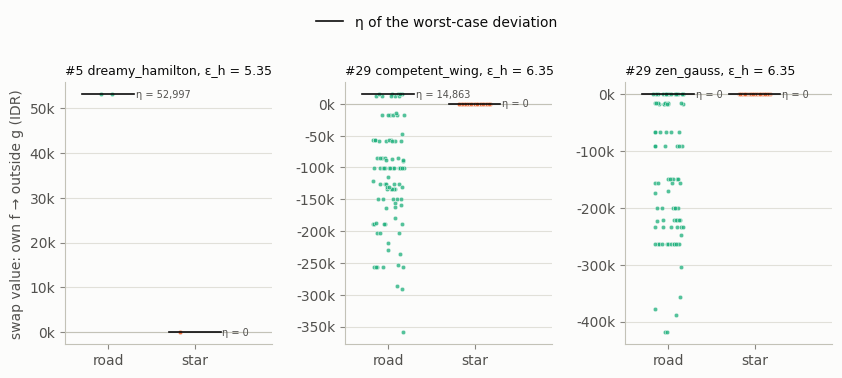

In [12]:
# Every one-for-one swap available to the matched high type at one point past saturation: own farmer f on its deviation's
# base route for an outside farmer g, valued with whole-route costs at the solve's payments. With linear costs (star) every
# swap is worth exactly 0; on the road network some are worth more than 0, and the best is worth exactly η.
FIG_POINTS = [(5, "dreamy_hamilton", 5.35), (29, "competent_wing", 6.35), (29, "zen_gauss", 6.35)]
rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, len(FIG_POINTS), figsize=(3.3 * len(FIG_POINTS), 3.4), squeeze=False,
                         gridspec_kw={"wspace": 0.35})
for ax, (i, h, e) in zip(axes.flat, FIG_POINTS):
    for k, arm in enumerate(ARMS):
        sv = swap_sets[(i, arm, round(e, 6), h)]["swap_value"].to_numpy()
        x = k + rng.uniform(-0.18, 0.18, len(sv))
        ax.plot(x, sv, "o", color=ARM_COLORS[arm], markersize=3.2, alpha=0.75, markeredgecolor=SURFACE,
                markeredgewidth=0.4, zorder=3)
        eta = swaps.query("instance == @i and arm == @arm and high_type == @h and abs(eps_h - @e) < 1e-9")["eta"].iloc[0]
        ax.plot([k - 0.3, k + 0.3], [eta, eta], color=INK, linewidth=1.2, zorder=4)
        ax.text(k + 0.32, eta, f"η = {eta:,.0f}", fontsize=7, color=INK_SECONDARY, va="center")
    ax.axhline(0, color=AXIS, linewidth=0.8, zorder=1)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["road", "star"])
    ax.set_xlim(-0.5, 1.9)
    ax.yaxis.set_major_formatter(thousands)
    ax.grid(axis="y")
    ax.set_axisbelow(True)
    ax.set_title(f"#{i} {h}, ε_h = {e}", loc="left", color=INK, fontsize=9)
axes[0, 0].set_ylabel("swap value: own f → outside g (IDR)")
fig.legend(handles=[Line2D([], [], color=INK, linewidth=1.2, label="η of the worst-case deviation")],
           loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=1)
plt.savefig(FIG_DIR / "swap_values.png", bbox_inches="tight", dpi=300)
plt.show()

## Why the high types get switched in and out: what each matching costs

Π = revenue − F − R − C, with F the farmer payments, R the intermediary profits (only matched high types are ever paid here), and C the collection cost. With revenue fixed,

  Π_I − Π_E = (T_E − T_I) − (C_I − C_E), where T = F + R is everything transferred.

- **The premium C_I − C_E is fixed.** Both matchings use `min_trucks` trucks, and routing cost depends only on the number of trucks, so the premium is the high types' extra fixed cost, Σ_high (ρ − 1)σ_ℓ.
- **The transfer saving T_E − T_I is what moves with ε_h.** Matching the high types means farmers no longer need to be paid to keep them out (F falls), but the high types must be paid their deviation profit (R rises).

The high types are matched exactly when the transfer saving exceeds the premium. How T_I splits into F and R can differ across optimal solutions; the range comes from the two extreme optimal solutions each solve saved. For #11, the approximate routing cost differs by up to 4,369 between the efficient-side and inefficient-side runs. Profit is unaffected, since a cheaper route lowers C and raises the deviating high type's outside option equally, but that noise moves between C and T.

In [13]:
dec_rows = []
for file in files:
    with gzip.open(file, "rt", encoding="utf-8") as f:
        payload = json.load(f)
    for run in payload["runs"]:
        psr = run["summary"]["platform_solve_result"]
        high = set(run["high_ids"])
        het = run["summary"]["params"]["het_costs"]

        def parts(res):
            return (sum(res["farmer_payments"].values()),
                    sum(v for t, v in res["intermediary_profits"].items() if t in high),
                    sum(v for t, v in res["intermediary_profits"].items() if t not in high))

        F, R_high, R_other = parts(psr["primary_result"])
        _, R_high_max, _ = parts(psr["max_intermediary_welfare_result"])
        _, R_high_min, _ = parts(psr["max_farmer_welfare_result"])
        matched = psr["primary_result"]["selected_intermediaries"]
        dec_rows.append({
            "instance": payload["instance_id"], "arm": run["arm"], "side": run["side"], "eps_h": run["eps_h"],
            "profit": psr["primary_result"]["platform_profit"], "C": psr["primary_result"]["expected_intermediary_cost"],
            "fixed_premium": sum(het[t] for t in matched), "F": F, "R_high": R_high, "R_other": R_other,
            "R_high_min": R_high_min, "R_high_max": R_high_max,
            "low_types": tuple(sorted(t for t in matched if t not in high)), "high_types": tuple(sorted(high)),
        })
dec = pd.DataFrame(dec_rows)
dec["T"] = dec["F"] + dec["R_high"] + dec["R_other"]
assert (dec["R_other"].abs() < 1e-6).all(), "a low or unmatched intermediary earns a profit"

D = dec.pivot_table(index=["instance", "arm", "eps_h"], columns="side",
                    values=["profit", "C", "T", "F", "R_high", "R_high_min", "R_high_max"]).reset_index()
D.columns = ["_".join(c).rstrip("_") for c in D.columns]
D["premium"] = D["C_inefficient"] - D["C_efficient"]              # extra collection cost of matching the high types
D["transfer_saving"] = D["T_efficient"] - D["T_inefficient"]      # transfers saved by matching them
D["farmer_saving"] = D["F_efficient"] - D["F_inefficient"]        # farmer payments saved (primary split)
D["high_profit"] = D["R_high_inefficient"]                        # paid to the matched high types (primary split)
D["gap"] = D["profit_inefficient"] - D["profit_efficient"]
assert np.allclose(D["gap"], D["transfer_saving"] - D["premium"], atol=1e-3)

# which intermediaries each side matches, and its collection cost
dec.groupby(["instance", "arm", "side"]).agg(
    high_types=("high_types", "first"), low_types=("low_types", lambda s: sorted(set(s))),
    fixed_cost_premium=("fixed_premium", "first"),
    collection_cost=("C", lambda s: f"{s.min():,.0f}" if np.ptp(s) < 1 else f"{s.min():,.0f} – {s.max():,.0f}"))

high_types  \
instance arm  side                                                             
5        road efficient                                   (dreamy_hamilton,)   
              inefficient                                 (dreamy_hamilton,)   
         star efficient                                   (dreamy_hamilton,)   
              inefficient                                 (dreamy_hamilton,)   
11       road efficient    (goofy_bell, practical_elion, unruffled_elbakyan)   
              inefficient  (goofy_bell, practical_elion, unruffled_elbakyan)   
         star efficient    (goofy_bell, practical_elion, unruffled_elbakyan)   
              inefficient  (goofy_bell, practical_elion, unruffled_elbakyan)   
29       road efficient                          (competent_wing, zen_gauss)   
              inefficient                        (competent_wing, zen_gauss)   
         star efficient                          (competent_wing, zen_gauss)   
              inefficient                        (competent_wing, zen_gauss)   

                                                                   low_types  \
instance arm  side                                                             
5        road efficient                   [(wizardly_tharp, wonderful_pare)]   
              inefficient                                [(wonderful_pare,)]   
         star efficient                   [(wizardly_tharp, wonderful_pare)]   
              inefficient                                [(wonderful_pare,)]   
11       road efficient    [(charming_merkle, festive_bassi, nice_mccarth...   
              inefficient                               [(charming_merkle,)]   
         star efficient    [(charming_merkle, festive_bassi, nice_mccarth...   
              inefficient                               [(charming_merkle,)]   
29       road efficient    [(heuristic_wright, thirsty_hoover, zealous_no...   
              inefficient                                [(thirsty_hoover,)]   
         star efficient    [(heuristic_wright, thirsty_hoover, zealous_no...   
              inefficient                                [(thirsty_hoover,)]   

                           fixed_cost_premium collection_cost  
instance arm  side                                             
5        road efficient                   0.0       2,535,699  
              inefficient            240000.0       2,775,699  
         star efficient                   0.0       3,598,582  
              inefficient            240000.0       3,838,582  
11       road efficient                   0.0       6,625,719  
              inefficient            288000.0       6,909,350  
         star efficient                   0.0      17,665,330  
              inefficient            288000.0      17,957,699  
29       road efficient                   0.0       4,626,751  
              inefficient            320000.0       4,946,751  
         star efficient                   0.0      12,263,693  
              inefficient            320000.0      12,583,693

In [14]:
# the decomposition at each instance's key points: before the first switch, inside the inefficient regime, after the last switch
KEY_POINTS = {5: [5.1, 5.25, 5.35, 5.5], 29: [6.1, 6.25, 6.35, 6.5], 11: [6.4, 6.6, 7.0, 7.6, 8.0]}
key = D[[any(np.isclose(e, KEY_POINTS[i])) for i, e in zip(D["instance"], D["eps_h"])]].copy()
key["high_profit_range"] = [f"{lo:,.0f} – {hi:,.0f}" if hi - lo > 100 else ""
                            for lo, hi in zip(key["R_high_min_inefficient"], key["R_high_max_inefficient"])]
money = ["farmer_saving", "high_profit", "transfer_saving", "premium", "gap"]
key[["instance", "arm", "eps_h", "farmer_saving", "high_profit", "high_profit_range", "transfer_saving", "premium", "gap"]].round({m: 0 for m in money})

,instance,arm,eps_h,farmer_saving,high_profit,high_profit_range,transfer_saving,premium,gap
4,5,road,5.10,1958139.0,1731221.0,,226918.0,240000.0,-13082.0
10,5,road,5.25,1987624.0,1739171.0,,248453.0,240000.0,8453.0
14,5,road,5.35,1987624.0,1744470.0,,243153.0,240000.0,3153.0
20,5,road,5.50,2146615.0,1911411.0,"1,646,419 – 1,911,418",235204.0,240000.0,-4796.0
29,5,star,5.10,1976471.0,1760000.0,,216471.0,240000.0,-23529.0
35,5,star,5.25,2011429.0,1760000.0,,251429.0,240000.0,11429.0
39,5,star,5.35,2011429.0,1760000.0,,251429.0,240000.0,11429.0
45,5,star,5.50,2011429.0,1760000.0,,251429.0,240000.0,11429.0
50,11,road,6.40,6090652.0,5520252.0,"3,406,142 – 9,016,738",570399.0,283631.0,286768.0
51,11,road,6.60,6252657.0,5762135.0,"3,591,124 – 9,201,591",490522.0,283631.0,206892.0


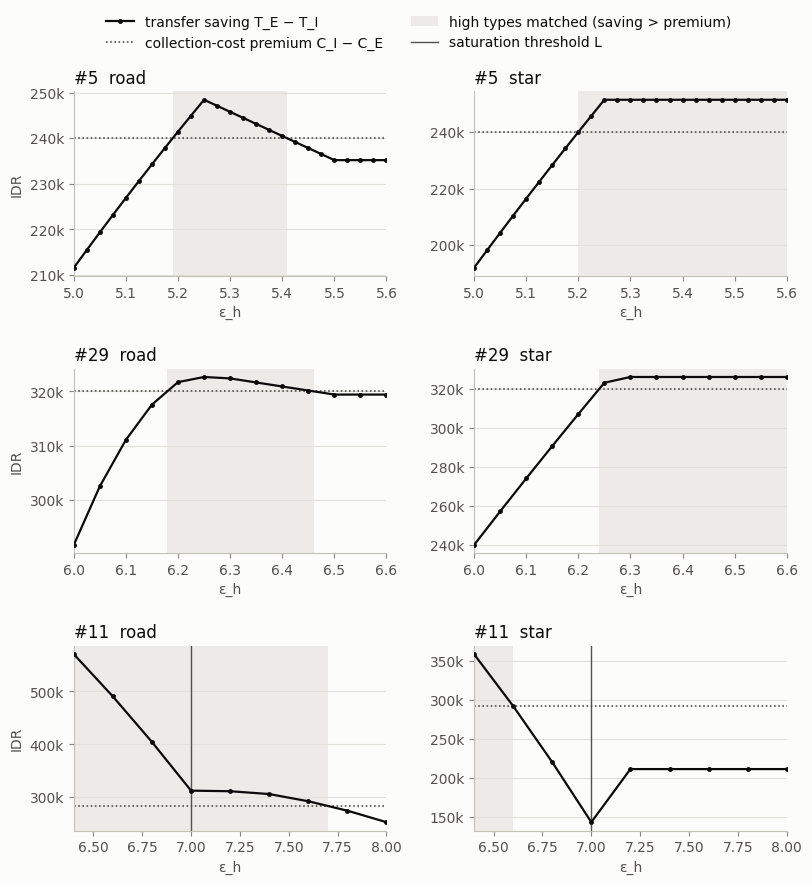

In [15]:
# transfer saving vs. premium: the high types are matched wherever the saving is above the premium
SAVING_COLOR, PREMIUM_COLOR = INK, INK_SECONDARY

fig, axes = plt.subplots(len(present), 2, figsize=(9.2, 3.2 * len(present)), squeeze=False,
                         gridspec_kw={"hspace": 0.5, "wspace": 0.28})
for row, i in enumerate(present):
    for col, arm in enumerate(ARMS):
        ax = axes[row, col]
        g = D.query("instance == @i and arm == @arm").sort_values("eps_h")
        eps = g["eps_h"].to_numpy()
        found = sorted(cross.query("instance == @i and arm == @arm")["crossing"].dropna())
        bounds = [eps.min(), *found, eps.max()]
        for x0, x1 in zip(bounds[:-1], bounds[1:]):
            if np.interp((x0 + x1) / 2, eps, g["gap"].to_numpy()) > 0:
                ax.axvspan(x0, x1, color=SHADE, linewidth=0, zorder=0)
        if eps.min() < L_of[i] < eps.max():
            ax.axvline(L_of[i], color=INK_SECONDARY, linewidth=1.0, zorder=1)
        ax.plot(eps, g["premium"], color=PREMIUM_COLOR, linewidth=1.2, linestyle=(0, (1, 1.5)), zorder=2)
        ax.plot(eps, g["transfer_saving"], color=SAVING_COLOR, linewidth=1.6, marker="o", markersize=2.5, zorder=4)
        ax.set_title(f"#{i}  {arm}", loc="left", color=INK)
        ax.set_xlim(eps.min(), eps.max())
        ax.yaxis.set_major_formatter(thousands)
        ax.grid(axis="y")
        ax.set_axisbelow(True)
        ax.set_xlabel("ε_h")

    axes[row, 0].set_ylabel("IDR")

fig.legend(handles=[
    Line2D([], [], color=SAVING_COLOR, linewidth=1.6, marker="o", markersize=2.5, label="transfer saving T_E − T_I"),
    Line2D([], [], color=PREMIUM_COLOR, linewidth=1.2, linestyle=(0, (1, 1.5)), label="collection-cost premium C_I − C_E"),
    Patch(facecolor=SHADE, label="high types matched (saving > premium)"),
    Line2D([], [], color=INK_SECONDARY, linewidth=1.0, label="saturation threshold L"),
], loc="lower center", bbox_to_anchor=(0.5, 0.91), ncol=2)
plt.savefig(FIG_DIR / "switch_decomposition.png", bbox_inches="tight", dpi=300)
plt.show()

In [16]:
# The matched high type's worst-case deviation, point by point: which two routes it mixes and with what
# probabilities, how that sets its profit, and how the inefficient profit compares with the efficient one.
#   A = the route with more of the high type's own farmers, B = the swap route (more outside farmers)
#   P(A)·out(A) + P(B)·out(B) = ε_h (the budget), and P(A)·value(A) + P(B)·value(B) = its profit
#   value = route revenue − its farmers' payments − collection cost − the high type's fixed cost (at the saved payments)
def mixing_table(i, high_type, arm):
    rows = []
    devs = dev.query("instance == @i and arm == @arm and side == 'inefficient' and high_type == @high_type").sort_values("eps_h")
    for r in devs.itertuples():
        routes = sorted(r.routes, key=lambda rt: (rt["out"], -rt["own"]))
        A, B = routes[0], routes[-1]
        ine = dec.query("instance == @i and arm == @arm and side == 'inefficient' and abs(eps_h - @r.eps_h) < 1e-9").iloc[0]
        eff = dec.query("instance == @i and arm == @arm and side == 'efficient' and abs(eps_h - @r.eps_h) < 1e-9").iloc[0]
        gap = ine["profit"] - eff["profit"]
        rows.append({
            "ε_h": r.eps_h,
            "A (own+out)": f"{A['own']:g}+{A['out']:g}", "value(A)": A["value"], "P(A)": A["weight"] if len(routes) > 1 else 1.0,
            "B (own+out)": f"{B['own']:g}+{B['out']:g}" if len(routes) > 1 else "", "value(B)": B["value"] if len(routes) > 1 else np.nan,
            "P(B)": B["weight"] if len(routes) > 1 else 0.0,
            "E[outside tons]": sum(rt["weight"] * rt["out"] for rt in routes),
            "high type profit": r.deviation_profit,
            "η": r.eta,
            "all high types' profit": ine["R_high"],
            "farmer payments (I)": ine["F"],
            "Π_I": ine["profit"],
            "farmer payments (E)": eff["F"],
            "Π_E": eff["profit"],
            "Π_I − Π_E": gap,
            "optimal": "inefficient" if gap > 0 else "efficient",
        })
    return pd.DataFrame(rows).set_index("ε_h")


money = ["value(A)", "value(B)", "high type profit", "η", "all high types' profit",
         "farmer payments (I)", "Π_I", "farmer payments (E)", "Π_E", "Π_I − Π_E"]
for i, h in [(5, "dreamy_hamilton"), (29, "competent_wing")]:
    for arm in ARMS:
        t = mixing_table(i, h, arm)
        print(f"#{i} {arm}: worst-case deviation of {h} (matched), and the two matchings' profits")
        display(t.style.format({**{c: "{:,.0f}" for c in money}, "P(A)": "{:.3f}", "P(B)": "{:.3f}", "E[outside tons]": "{:.3f}"}, na_rep="").format_index("{:.3f}"))
print("Notes: on the road network the split between farmer payments and the high types' profit is not always unique "
      "(e.g. #29 at ε_h = 6.15, and #5 from 5.5), so route values and the high type's profit can step off their line there; "
      "Π_I and Π_E are unique.")


#5 road: worst-case deviation of dreamy_hamilton (matched), and the two matchings' profits


,A (own+out),value(A),P(A),B (own+out),value(B),P(B),E[outside tons],high type profit,η,all high types' profit,farmer payments (I),Π_I,farmer payments (E),Π_E,Π_I − Π_E,optimal
ε_h,,,,,,,,,,,,,,,,
5.000,2+5,"1,725,921",1.000,,,0.000,5.000,"1,725,921","387,013","1,725,921","15,995,351","-392,971","17,932,850","-364,549","-28,422",efficient
5.025,2+5,"1,725,921",0.975,1+6,"1,778,919",0.025,5.025,"1,727,246","52,997","1,727,246","15,995,351","-394,296","17,938,087","-369,786","-24,510",efficient
5.050,2+5,"1,725,921",0.950,1+6,"1,778,919",0.050,5.050,"1,728,571","52,997","1,728,571","15,995,351","-395,621","17,943,272","-374,971","-20,650",efficient
5.075,2+5,"1,725,921",0.925,1+6,"1,778,919",0.075,5.075,"1,729,896","52,997","1,729,896","15,995,351","-396,946","17,948,406","-380,105","-16,841",efficient
5.100,2+5,"1,725,921",0.900,1+6,"1,778,919",0.100,5.100,"1,731,221","52,997","1,731,221","15,995,351","-398,271","17,953,489","-385,189","-13,082",efficient
5.125,2+5,"1,725,921",0.875,1+6,"1,778,919",0.125,5.125,"1,732,546","52,997","1,732,546","15,995,351","-399,596","17,958,523","-390,223","-9,373",efficient
5.150,2+5,"1,725,921",0.850,1+6,"1,778,919",0.150,5.150,"1,733,871","52,997","1,733,871","15,995,351","-400,921","17,963,508","-395,208","-5,713",efficient
5.175,2+5,"1,725,921",0.825,1+6,"1,778,919",0.175,5.175,"1,735,196","52,997","1,735,196","15,995,351","-402,246","17,968,445","-400,145","-2,101",efficient
5.200,2+5,"1,725,921",0.800,1+6,"1,778,919",0.200,5.200,"1,736,521","52,997","1,736,521","15,995,351","-403,571","17,973,335","-405,034","1,463",inefficient


#5 star: worst-case deviation of dreamy_hamilton (matched), and the two matchings' profits


,A (own+out),value(A),P(A),B (own+out),value(B),P(B),E[outside tons],high type profit,η,all high types' profit,farmer payments (I),Π_I,farmer payments (E),Π_E,Π_I − Π_E,optimal
ε_h,,,,,,,,,,,,,,,,
5.000,2+5,"1,760,000",1.000,,,0.000,5.000,"1,760,000","400,000","1,760,000","14,905,418","-400,000","16,857,418","-352,000","-48,000",efficient
5.025,2+5,"1,760,000",1.000,,,0.000,5.000,"1,760,000",0,"1,760,000","14,905,418","-400,000","16,863,627","-358,209","-41,791",efficient
5.050,2+5,"1,760,000",0.950,1+6,"1,760,000",0.050,5.050,"1,760,000",0,"1,760,000","14,905,418","-400,000","16,869,775","-364,356","-35,644",efficient
5.075,2+5,"1,760,000",1.000,,,0.000,5.000,"1,760,000",0,"1,760,000","14,905,418","-400,000","16,875,862","-370,443","-29,557",efficient
5.100,2+5,"1,760,000",0.900,1+6,"1,760,000",0.100,5.100,"1,760,000",0,"1,760,000","14,905,418","-400,000","16,881,889","-376,471","-23,529",efficient
5.125,2+5,"1,760,000",1.000,,,0.000,5.000,"1,760,000",0,"1,760,000","14,905,418","-400,000","16,887,857","-382,439","-17,561",efficient
5.150,2+5,"1,760,000",1.000,,,0.000,5.000,"1,760,000",0,"1,760,000","14,905,418","-400,000","16,893,768","-388,350","-11,650",efficient
5.175,2+5,"1,760,000",1.000,,,0.000,5.000,"1,760,000",0,"1,760,000","14,905,418","-400,000","16,899,621","-394,203","-5,797",efficient
5.200,2+5,"1,760,000",1.000,,,0.000,5.000,"1,760,000",0,"1,760,000","14,905,418","-400,000","16,905,418","-400,000",-0,efficient


#29 road: worst-case deviation of competent_wing (matched), and the two matchings' profits


,A (own+out),value(A),P(A),B (own+out),value(B),P(B),E[outside tons],high type profit,η,all high types' profit,farmer payments (I),Π_I,farmer payments (E),Π_E,Π_I − Π_E,optimal
ε_h,,,,,,,,,,,,,,,,
6.000,7+6,"4,142,801",1.000,,,0.000,6.000,"4,142,801","324,614","8,424,194","54,845,002","-364,948","63,560,943","-336,694","-28,254",efficient
6.050,7+6,"4,151,102",0.993,0+13,"4,255,146",0.007,6.050,"4,151,845","14,863","8,406,991","54,862,949","-365,691","63,572,488","-348,239","-17,452",efficient
6.100,7+6,"4,151,102",0.986,0+13,"4,255,146",0.014,6.100,"4,152,588","14,863","8,407,734","54,862,949","-366,435","63,581,773","-357,524","-8,910",efficient
6.150,7+6,"4,136,474",0.979,0+13,"4,240,517",0.021,6.150,"4,138,703","14,863","8,379,220","54,892,206","-367,178","63,588,999","-364,751","-2,427",efficient
6.200,7+6,"4,151,102",0.971,0+13,"4,255,146",0.029,6.200,"4,154,075","14,863","8,409,220","54,862,949","-367,921","63,593,881","-369,633","1,712",inefficient
6.250,7+6,"4,151,102",0.964,0+13,"4,255,146",0.036,6.250,"4,154,818","14,863","8,409,964","54,862,949","-368,664","63,595,569","-371,320","2,656",inefficient
6.300,7+6,"4,151,102",0.957,0+13,"4,255,146",0.043,6.300,"4,155,561","14,863","8,410,707","54,862,949","-369,407","63,596,049","-371,801","2,393",inefficient
6.350,7+6,"4,151,102",0.950,0+13,"4,255,146",0.050,6.350,"4,156,304","14,863","8,411,450","54,862,949","-370,150","63,596,049","-371,801","1,650",inefficient
6.400,7+6,"4,151,102",0.943,0+13,"4,255,146",0.057,6.400,"4,157,047","14,863","8,412,193","54,862,949","-370,894","63,596,049","-371,801",907,inefficient


#29 star: worst-case deviation of competent_wing (matched), and the two matchings' profits


,A (own+out),value(A),P(A),B (own+out),value(B),P(B),E[outside tons],high type profit,η,all high types' profit,farmer payments (I),Π_I,farmer payments (E),Π_E,Π_I − Π_E,optimal
ε_h,,,,,,,,,,,,,,,,
6.000,7+0,"240,000",0.250,3+8,"3,440,000",0.750,6.000,"2,640,000","400,000","5,280,000","50,387,307","-400,000","55,907,307","-320,000","-80,000",efficient
6.050,7+6,"4,240,000",0.988,3+10,"4,240,000",0.012,6.050,"4,240,000",0,"8,480,000","47,187,307","-400,000","55,924,497","-337,190","-62,810",efficient
6.100,7+6,"4,240,000",0.967,4+9,"4,240,000",0.033,6.100,"4,240,000",0,"8,480,000","47,187,307","-400,000","55,941,405","-354,098","-45,902",efficient
6.150,7+6,"4,240,000",0.950,4+9,"4,240,000",0.050,6.150,"4,240,000",0,"8,480,000","47,187,307","-400,000","55,958,039","-370,732","-29,268",efficient
6.200,7+6,"4,240,000",0.950,3+10,"4,240,000",0.050,6.200,"4,240,000",0,"8,480,000","47,187,307","-400,000","55,974,404","-387,097","-12,903",efficient
6.250,7+6,"4,240,000",0.917,4+9,"4,240,000",0.083,6.250,"4,240,000",0,"8,480,000","47,187,307","-400,000","55,990,507","-403,200","3,200",inefficient
6.300,7+6,"4,240,000",0.900,4+9,"4,240,000",0.100,6.300,"4,240,000",0,"8,480,000","47,187,307","-400,000","55,993,461","-406,154","6,154",inefficient
6.350,7+6,"4,240,000",0.825,5+8,"4,240,000",0.175,6.350,"4,240,000",0,"8,480,000","47,187,307","-400,000","55,993,461","-406,154","6,154",inefficient
6.400,7+6,"4,240,000",0.900,3+10,"4,240,000",0.100,6.400,"4,240,000",0,"8,480,000","47,187,307","-400,000","55,993,461","-406,154","6,154",inefficient


Notes: on the road network the split between farmer payments and the high types' profit is not always unique (e.g. #29 at ε_h = 6.15, and #5 from 5.5), so route values and the high type's profit can step off their line there; Π_I and Π_E are unique.


In [17]:
# Tracking the matched high type's worst-case deviation over ε_h: its value, its slope η, and which farmers it takes.
# A farmer's inclusion probability is Σ over the deviation's routes of P(route) · 1[farmer on route]: 1 = always taken,
# between 0 and 1 = being swapped in or out as the budget grows. Where η = 0 the routes tie in value, so the mix (and these
# probabilities) is only one of many worst cases.
def inclusion(i, high_type, arm):
    devs = dev.query("instance == @i and arm == @arm and side == 'inefficient' and high_type == @high_type").sort_values("eps_h")
    probs, info = {}, []
    for r in devs.itertuples():
        p = {}
        for route in r.routes:
            for f in route["farmers"]:
                key = (("own" if f["own"] else "out"), f["id"])
                p[key] = p.get(key, 0.0) + route["weight"]
        probs[r.eps_h] = p
        info.append({"ε_h": r.eps_h, "deviation value": r.deviation_profit, "η": r.eta,
                     "E[outside tons]": sum(route["weight"] * route["out"] for route in r.routes), "routes in mix": len(r.routes)})
    P = pd.DataFrame(probs).fillna(0.0)
    P = P.loc[sorted(P.index, key=lambda k: (k[0] != "own", -P.loc[[k]].to_numpy().mean(), k[1]))]   # own first, then by use
    P.index = [f"{kind}: {fid}" for kind, fid in P.index]
    return P, pd.DataFrame(info).set_index("ε_h")


def swapped(P, eps):
    col = P[eps].round(3)
    part = col[(col > 1e-3) & (col < 1 - 1e-3)]
    return ", ".join(f"{name.split(': ')[1]} ({kind} {v:.3f})" for name, v in part.items() for kind in [name.split(":")[0]])


for i, h in [(5, "dreamy_hamilton"), (29, "competent_wing")]:
    for arm in ARMS:
        P, info = inclusion(i, h, arm)
        info["always taken"] = [", ".join(n.split(": ")[1] for n, v in P[e].items() if v > 1 - 1e-3) for e in info.index]
        info["partly taken (inclusion probability)"] = [swapped(P, e) for e in info.index]
        print(f"#{i} {arm}: worst-case deviation of the matched {h}")
        display(info.style.format({"deviation value": "{:,.0f}", "η": "{:,.0f}", "E[outside tons]": "{:.3f}"})
                .format_index("{:.3f}"))

# The swap between the two routes the deviation mixes (A: more own farmers, B: more outside farmers).
# Route-level numbers are exact: value(B) − value(A) = (margin of B − margin of A) − (cost of B − cost of A), and divided by
# the extra outside tons it equals η.
# Several routes can tie in value, so which pair the deviation returns, and hence how the gain splits between payment
# ("margin") and routing ("cost"), is not unique; the net gain per outside ton (η) is.
SWAP_DETAIL_EPS = {5: 5.35, 29: 6.35}


def swap_pairs(i, high_type, arm):
    rows, detail = [], []
    devs = dev.query("instance == @i and arm == @arm and side == 'inefficient' and high_type == @high_type").sort_values("eps_h")
    for r in devs.itertuples():
        if len(r.routes) < 2:
            continue
        A, B = sorted(r.routes, key=lambda rt: (rt["out"], -rt["own"]))[::len(r.routes) - 1]
        a_ids, b_ids = {f["id"] for f in A["farmers"]}, {f["id"] for f in B["farmers"]}
        dropped = [f for f in A["farmers"] if f["id"] not in b_ids]
        added = [f for f in B["farmers"] if f["id"] not in a_ids]
        margin_gain = sum(f["margin"] for f in B["farmers"]) - sum(f["margin"] for f in A["farmers"])
        cost_added = B["route_cost"] - A["route_cost"]
        extra_out = B["out"] - A["out"]
        rows.append({
            "ε_h": r.eps_h,
            "dropped (A only)": ", ".join(f"{f['id']}{' (own)' if f['own'] else ''}" for f in dropped),
            "added (B only)": ", ".join(f"{f['id']}{' (own)' if f['own'] else ''}" for f in added),
            "extra outside tons": extra_out,
            "margin gained": margin_gain, "route cost added": cost_added,
            "value(B) − value(A)": B["value"] - A["value"],
            "net per outside ton": (B["value"] - A["value"]) / extra_out if extra_out else np.nan,
            "η": r.eta,
        })
    return pd.DataFrame(rows).set_index("ε_h"), pd.DataFrame(detail)


swap_money = ["margin gained", "route cost added", "value(B) − value(A)", "net per outside ton", "η"]
for i, h in [(5, "dreamy_hamilton"), (29, "competent_wing")]:
    for arm in ARMS:
        pairs, detail = swap_pairs(i, h, arm)
        print(f"#{i} {arm}: the swap between routes A and B in {h}'s worst-case deviation")
        display(pairs.style.format({**{c: "{:,.0f}" for c in swap_money}, "extra outside tons": "{:g}"}, na_rep="")
                .format_index("{:.3f}"))


# Every one-for-one swap available at one point, valued with whole-route costs (no per-farmer cost split):
#   swap value(f → g) = (margin_g − margin_f) − [c(S − f + g) − c(S)],  S = the deviation's base route.
# The best swap is worth η on the road network; every swap is worth 0 with linear costs.
TOP_SWAPS = 8
for i, h in [(5, "dreamy_hamilton"), (29, "competent_wing")]:
    e = SWAP_DETAIL_EPS[i]
    for arm in ARMS:
        t = swap_sets[(i, arm, round(e, 6), h)].sort_values("swap_value", ascending=False)
        eta = swaps.query("instance == @i and arm == @arm and high_type == @h and abs(eps_h - @e) < 1e-9")["eta"].iloc[0]
        print(f"#{i} {arm}, {h}, ε_h = {e}: {len(t)} swaps, {int((t['swap_value'] > 1).sum())} worth more than 0; "
              f"best {t['swap_value'].iloc[0]:,.0f}, η = {eta:,.0f}" + (f" (top {TOP_SWAPS} shown)" if len(t) > TOP_SWAPS else ""))
        display(t.head(TOP_SWAPS)[["drop", "add", "margin_gain", "route_cost_change", "swap_value"]]
                .rename(columns={"drop": "drop (own)", "add": "add (outside)", "margin_gain": "margin gained",
                                 "route_cost_change": "route cost change", "swap_value": "swap value"})
                .style.format({"margin gained": "{:,.0f}", "route cost change": "{:,.0f}", "swap value": "{:,.0f}"})
                .hide(axis="index"))
print("Best swap at every ε_h:")
display(swaps.query("high_type in ['dreamy_hamilton', 'competent_wing']").sort_values(["instance", "arm", "eps_h"])
        [["instance", "arm", "eps_h", "base route (own+out)", "best swap", "best swap value", "eta", "positive swaps"]]
        .style.format({"best swap value": "{:,.0f}", "eta": "{:,.0f}", "eps_h": "{:.3f}"}).hide(axis="index"))

#5 road: worst-case deviation of the matched dreamy_hamilton


,deviation value,η,E[outside tons],routes in mix,always taken,partly taken (inclusion probability)
ε_h,,,,,,
5.000,"1,725,921","387,013",5.000,1,"dreamy_hamilton_f0, dreamy_hamilton_f1, ecstatic_goldwasser_f0, magical_spence_f0, silly_carver_f0, suspicious_kare_f0, wonderful_pare_f0",
5.025,"1,727,246","52,997",5.025,2,"dreamy_hamilton_f0, ecstatic_goldwasser_f0, magical_spence_f0, silly_carver_f0, suspicious_kare_f0, wonderful_pare_f0","dreamy_hamilton_f1 (own 0.975), wizardly_tharp_f0 (out 0.025)"
5.050,"1,728,571","52,997",5.050,2,"dreamy_hamilton_f0, ecstatic_goldwasser_f0, magical_spence_f0, silly_carver_f0, suspicious_kare_f0, wonderful_pare_f0","dreamy_hamilton_f1 (own 0.950), wizardly_tharp_f0 (out 0.050)"
5.075,"1,729,896","52,997",5.075,2,"dreamy_hamilton_f0, ecstatic_goldwasser_f0, magical_spence_f0, silly_carver_f0, suspicious_kare_f0, wonderful_pare_f0","dreamy_hamilton_f1 (own 0.925), wizardly_tharp_f0 (out 0.075)"
5.100,"1,731,221","52,997",5.100,2,"dreamy_hamilton_f0, ecstatic_goldwasser_f0, magical_spence_f0, silly_carver_f0, suspicious_kare_f0, wonderful_pare_f0","dreamy_hamilton_f1 (own 0.900), wizardly_tharp_f0 (out 0.100)"
5.125,"1,732,546","52,997",5.125,2,"dreamy_hamilton_f0, ecstatic_goldwasser_f0, magical_spence_f0, silly_carver_f0, suspicious_kare_f0, wonderful_pare_f0","dreamy_hamilton_f1 (own 0.875), wizardly_tharp_f0 (out 0.125)"
5.150,"1,733,871","52,997",5.150,2,"dreamy_hamilton_f0, ecstatic_goldwasser_f0, magical_spence_f0, silly_carver_f0, suspicious_kare_f0, wonderful_pare_f0","dreamy_hamilton_f1 (own 0.850), wizardly_tharp_f0 (out 0.150)"
5.175,"1,735,196","52,997",5.175,2,"dreamy_hamilton_f0, ecstatic_goldwasser_f0, magical_spence_f0, silly_carver_f0, suspicious_kare_f0, wonderful_pare_f0","dreamy_hamilton_f1 (own 0.825), wizardly_tharp_f0 (out 0.175)"
5.200,"1,736,521","52,997",5.200,2,"dreamy_hamilton_f0, ecstatic_goldwasser_f0, magical_spence_f0, silly_carver_f0, suspicious_kare_f0, wonderful_pare_f0","dreamy_hamilton_f1 (own 0.800), wizardly_tharp_f0 (out 0.200)"


#5 star: worst-case deviation of the matched dreamy_hamilton


,deviation value,η,E[outside tons],routes in mix,always taken,partly taken (inclusion probability)
ε_h,,,,,,
5.000,"1,760,000","400,000",5.000,1,"dreamy_hamilton_f1, dreamy_hamilton_f0, magical_spence_f0, silly_carver_f0, suspicious_kare_f0, wonderful_pare_f0, ecstatic_goldwasser_f0",
5.025,"1,760,000",0,5.000,1,"dreamy_hamilton_f1, dreamy_hamilton_f0, magical_spence_f0, silly_carver_f0, suspicious_kare_f0, wonderful_pare_f0, ecstatic_goldwasser_f0",
5.050,"1,760,000",0,5.050,2,"dreamy_hamilton_f1, magical_spence_f0, silly_carver_f0, suspicious_kare_f0, wizardly_tharp_f0, ecstatic_goldwasser_f0","dreamy_hamilton_f0 (own 0.950), wonderful_pare_f0 (out 0.050)"
5.075,"1,760,000",0,5.000,1,"dreamy_hamilton_f1, dreamy_hamilton_f0, magical_spence_f0, silly_carver_f0, suspicious_kare_f0, wonderful_pare_f0, ecstatic_goldwasser_f0",
5.100,"1,760,000",0,5.100,2,"dreamy_hamilton_f1, magical_spence_f0, silly_carver_f0, suspicious_kare_f0, wizardly_tharp_f0, ecstatic_goldwasser_f0","dreamy_hamilton_f0 (own 0.900), wonderful_pare_f0 (out 0.100)"
5.125,"1,760,000",0,5.000,1,"dreamy_hamilton_f1, dreamy_hamilton_f0, magical_spence_f0, silly_carver_f0, suspicious_kare_f0, wonderful_pare_f0, ecstatic_goldwasser_f0",
5.150,"1,760,000",0,5.000,1,"dreamy_hamilton_f1, dreamy_hamilton_f0, magical_spence_f0, silly_carver_f0, suspicious_kare_f0, wizardly_tharp_f0, ecstatic_goldwasser_f0",
5.175,"1,760,000",0,5.000,1,"dreamy_hamilton_f1, dreamy_hamilton_f0, magical_spence_f0, silly_carver_f0, suspicious_kare_f0, wizardly_tharp_f0, ecstatic_goldwasser_f0",
5.200,"1,760,000",0,5.000,1,"dreamy_hamilton_f1, dreamy_hamilton_f0, magical_spence_f0, silly_carver_f0, suspicious_kare_f0, wizardly_tharp_f0, ecstatic_goldwasser_f0",


#29 road: worst-case deviation of the matched competent_wing


,deviation value,η,E[outside tons],routes in mix,always taken,partly taken (inclusion probability)
ε_h,,,,,,
6.000,"4,142,801","324,614",6.000,1,"competent_wing_f0, competent_wing_f1, competent_wing_f2, competent_wing_f3, competent_wing_f4, competent_wing_f5, competent_wing_f6, unruffled_mayer_f0, funny_wescoff_f0, thirsty_napier_f0, elegant_chebyshev_f0, sweet_shirley_f0, xenodochial_hopper_f0",
6.050,"4,151,845","14,863",6.050,2,"unruffled_mayer_f0, funny_wescoff_f0, thirsty_napier_f0, sweet_shirley_f0, xenodochial_hopper_f0","competent_wing_f0 (own 0.993), competent_wing_f1 (own 0.993), competent_wing_f2 (own 0.993), competent_wing_f3 (own 0.993), competent_wing_f4 (own 0.993), competent_wing_f5 (own 0.993), competent_wing_f6 (own 0.993), elegant_chebyshev_f0 (out 0.007), zealous_northcutt_f0 (out 0.993), heuristic_wright_f0 (out 0.007), zen_gauss_f4 (out 0.007), zen_gauss_f2 (out 0.007), zen_gauss_f0 (out 0.007), condescending_einstein_f0 (out 0.007), zen_gauss_f3 (out 0.007), thirsty_hoover_f0 (out 0.007)"
6.100,"4,152,588","14,863",6.100,2,"unruffled_mayer_f0, keen_euclid_f0, xenodochial_hopper_f0","competent_wing_f0 (own 0.986), competent_wing_f1 (own 0.986), competent_wing_f2 (own 0.986), competent_wing_f3 (own 0.986), competent_wing_f4 (own 0.986), competent_wing_f5 (own 0.986), competent_wing_f6 (own 0.986), funny_wescoff_f0 (out 0.986), thirsty_napier_f0 (out 0.986), elegant_chebyshev_f0 (out 0.986), heuristic_wright_f0 (out 0.014), zen_gauss_f6 (out 0.014), zen_gauss_f1 (out 0.014), crazy_darwin_f0 (out 0.014), zen_gauss_f5 (out 0.014), zen_gauss_f0 (out 0.014), condescending_einstein_f0 (out 0.014), zen_gauss_f3 (out 0.014), thirsty_hoover_f0 (out 0.014), eager_leakey_f0 (out 0.014)"
6.150,"4,138,703","14,863",6.150,2,"funny_wescoff_f0, keen_euclid_f0, sweet_shirley_f0, xenodochial_hopper_f0","competent_wing_f0 (own 0.979), competent_wing_f1 (own 0.979), competent_wing_f2 (own 0.979), competent_wing_f3 (own 0.979), competent_wing_f4 (own 0.979), competent_wing_f5 (own 0.979), competent_wing_f6 (own 0.979), thirsty_napier_f0 (out 0.979), elegant_chebyshev_f0 (out 0.979), heuristic_wright_f0 (out 0.021), zen_gauss_f4 (out 0.021), zen_gauss_f6 (out 0.021), zen_gauss_f2 (out 0.021), zen_gauss_f1 (out 0.021), crazy_darwin_f0 (out 0.021), zen_gauss_f5 (out 0.021), zen_gauss_f0 (out 0.021), condescending_einstein_f0 (out 0.021)"
6.200,"4,154,075","14,863",6.200,2,"unruffled_mayer_f0, funny_wescoff_f0, thirsty_napier_f0, keen_euclid_f0, elegant_chebyshev_f0, zealous_northcutt_f0","competent_wing_f0 (own 0.971), competent_wing_f1 (own 0.971), competent_wing_f2 (own 0.971), competent_wing_f3 (own 0.971), competent_wing_f4 (own 0.971), competent_wing_f5 (own 0.971), competent_wing_f6 (own 0.971), xenodochial_hopper_f0 (out 0.029), heuristic_wright_f0 (out 0.029), zen_gauss_f6 (out 0.029), zen_gauss_f5 (out 0.029), condescending_einstein_f0 (out 0.029), zen_gauss_f3 (out 0.029), eager_leakey_f0 (out 0.029)"
6.250,"4,154,818","14,863",6.250,2,"unruffled_mayer_f0, funny_wescoff_f0, thirsty_napier_f0, elegant_chebyshev_f0, xenodochial_hopper_f0","competent_wing_f0 (own 0.964), competent_wing_f1 (own 0.964), competent_wing_f2 (own 0.964), competent_wing_f3 (own 0.964), competent_wing_f4 (own 0.964), competent_wing_f5 (own 0.964), competent_wing_f6 (own 0.964), keen_euclid_f0 (out 0.964), heuristic_wright_f0 (out 0.036), zen_gauss_f4 (out 0.036), zen_gauss_f6 (out 0.036), zen_gauss_f1 (out 0.036), zen_gauss_f5 (out 0.036), zen_gauss_f0 (out 0.036), condescending_einstein_f0 (out 0.036), zen_gauss_f3 (out 0.036)"
6.300,"4,155,561","14,863",6.300,2,"unruffled_mayer_f0, funny_wescoff_f0, keen_euclid_f0, sweet_shirley_f0","competent_wing_f0 (own 0.957), competent_wing_f1 (own 0.957), competent_wing_f2 (own 0.957), competent_wing_f3 (own 0.957), competent_wing_f4 (own 0.957), competent_wing_f5 (own 0.957), competent_wing_f6 (own 0.957), thirsty_napier_f0 (out 0.957), elegant_chebyshev_f0 (out 0.957), zealous_northcutt_f0 (out 0.043), h

... (16 outputs left out)

#29 star, competent_wing, ε_h = 6.35: 98 swaps, 0 worth more than 0; best 0, η = 0 (top 8 shown)


drop (own),add (outside),margin gained,route cost change,swap value
competent_wing_f3,zen_gauss_f3,"225,516","225,516",0
competent_wing_f3,unruffled_mayer_f0,"103,914","103,914",0
competent_wing_f3,condescending_einstein_f0,"241,010","241,010",0
competent_wing_f3,keen_euclid_f0,"-45,961","-45,961",0
competent_wing_f3,zealous_northcutt_f0,"-34,720","-34,720",0
competent_wing_f3,heuristic_wright_f0,"266,841","266,841",0
competent_wing_f2,zen_gauss_f3,"293,953","293,953",0
competent_wing_f3,thirsty_napier_f0,"135,996","135,996",0


Best swap at every ε_h:


instance,arm,eps_h,base route (own+out),best swap,best swap value,eta,positive swaps
5,road,5.000,2+5,dreamy_hamilton_f1 → wizardly_tharp_f0,"52,997","387,013",2
5,road,5.025,2+5,dreamy_hamilton_f1 → wizardly_tharp_f0,"52,997","52,997",2
5,road,5.050,2+5,dreamy_hamilton_f1 → wizardly_tharp_f0,"52,997","52,997",2
5,road,5.075,2+5,dreamy_hamilton_f1 → wizardly_tharp_f0,"52,997","52,997",2
5,road,5.100,2+5,dreamy_hamilton_f1 → wizardly_tharp_f0,"52,997","52,997",2
5,road,5.125,2+5,dreamy_hamilton_f1 → wizardly_tharp_f0,"52,997","52,997",2
5,road,5.150,2+5,dreamy_hamilton_f1 → wizardly_tharp_f0,"52,997","52,997",2
5,road,5.175,2+5,dreamy_hamilton_f1 → wizardly_tharp_f0,"52,997","52,997",2
5,road,5.200,2+5,dreamy_hamilton_f1 → wizardly_tharp_f0,"52,997","52,997",2
5,road,5.225,2+5,dreamy_hamilton_f1 → wizardly_tharp_f0,"52,997","52,997",2


In [18]:
# #5: the full routes behind the swap, with whole-route costs (no per-farmer cost split).
# For each of the high type's own farmers on its deviation's base route, the route with that farmer's slot filled by
# (a) the own farmer itself or (b) each outside farmer not on the route; the other six farmers are shared. Route value =
# margins − route cost − fixed cost − the high type's extra fixed cost, at the inefficient solve's payments.
# Δ columns: change from keeping the own farmer in the slot; Δ route value = Δ margin − Δ route cost.
SLOT_EPS = 5.35
slot_rows = json.loads((RESULTS_14 / "swaps_5.json").read_text())["rows"]
for arm in ARMS:
    r = next(x for x in slot_rows if x["arm"] == arm and np.isclose(x["eps_h"], SLOT_EPS) and x["high_type"] == "dreamy_hamilton")
    t = pd.DataFrame(r["slots"])
    for f, g in t.groupby("slot_of", sort=False):
        own = g.loc[g["candidate"] == f].iloc[0]
        # changes relative to keeping the own farmer in the slot: Δ route value = Δ margin − Δ route cost
        g = g.assign(**{"Δ margin": g["margin"] - own["margin"], "Δ route cost": g["route_cost"] - own["route_cost"],
                        "Δ route value": g["route_value"] - own["route_value"]})
        print(f"#5 {arm}, ε_h = {SLOT_EPS} (η = {r['eta']:,.0f}): slot of {f}; shared farmers: {', '.join(g['shared_farmers'].iloc[0])}")
        display(g[["candidate", "own", "payment", "margin", "route_cost", "route_value", "Δ margin", "Δ route cost", "Δ route value"]]
                .rename(columns={"candidate": "farmer in the slot", "route_cost": "route cost with",
                                 "route_value": "route value"})
                .style.format({c: "{:,.0f}" for c in ["payment", "margin", "route cost with", "route value"]}
                              | {c: "{:+,.0f}" for c in ["Δ margin", "Δ route cost", "Δ route value"]}).hide(axis="index"))


#5 road, ε_h = 5.35 (η = 52,997): slot of dreamy_hamilton_f0; shared farmers: dreamy_hamilton_f1, ecstatic_goldwasser_f0, magical_spence_f0, silly_carver_f0, suspicious_kare_f0, wonderful_pare_f0


farmer in the slot,own,payment,margin,route cost with,route value,Δ margin,Δ route cost,Δ route value
dreamy_hamilton_f0,True,"2,075,760","437,240","861,021","1,725,921",+0,+0,+0
wizardly_tharp_f0,False,"2,031,293","481,707","852,491","1,778,919","+44,466","-8,531","+52,997"


#5 road, ε_h = 5.35 (η = 52,997): slot of dreamy_hamilton_f1; shared farmers: dreamy_hamilton_f0, ecstatic_goldwasser_f0, magical_spence_f0, silly_carver_f0, suspicious_kare_f0, wonderful_pare_f0


farmer in the slot,own,payment,margin,route cost with,route value,Δ margin,Δ route cost,Δ route value
dreamy_hamilton_f1,True,"2,058,062","454,938","861,021","1,725,921",+0,+0,+0
wizardly_tharp_f0,False,"2,031,293","481,707","834,793","1,778,919","+26,768","-26,229","+52,997"


#5 star, ε_h = 5.35 (η = 0): slot of dreamy_hamilton_f0; shared farmers: dreamy_hamilton_f1, magical_spence_f0, silly_carver_f0, suspicious_kare_f0, wizardly_tharp_f0, wonderful_pare_f0


farmer in the slot,own,payment,margin,route cost with,route value,Δ margin,Δ route cost,Δ route value
dreamy_hamilton_f0,True,"1,973,230","539,770","1,685,742","1,760,000",+0,+0,+0
ecstatic_goldwasser_f0,False,"1,800,160","712,840","1,858,812","1,760,000","+173,070","+173,070",-0


#5 star, ε_h = 5.35 (η = 0): slot of dreamy_hamilton_f1; shared farmers: dreamy_hamilton_f0, magical_spence_f0, silly_carver_f0, suspicious_kare_f0, wizardly_tharp_f0, wonderful_pare_f0


farmer in the slot,own,payment,margin,route cost with,route value,Δ margin,Δ route cost,Δ route value
dreamy_hamilton_f1,True,"2,012,094","500,906","1,685,742","1,760,000",+0,+0,+0
ecstatic_goldwasser_f0,False,"1,800,160","712,840","1,897,675","1,760,000","+211,933","+211,933",-0


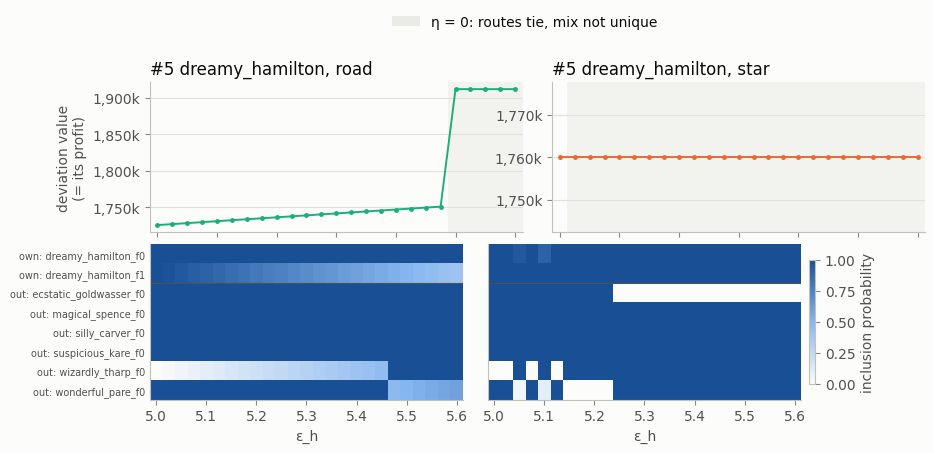

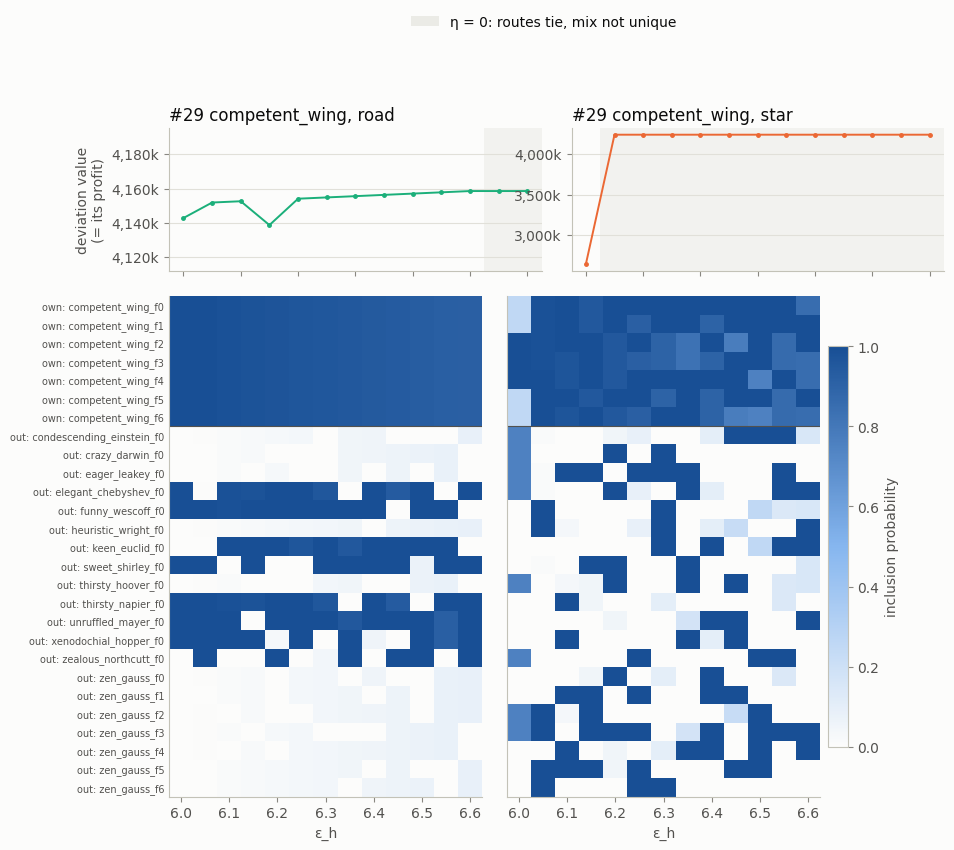

Reading the heatmaps:
- #5 road: one swap. dreamy_hamilton_f1 (own) is phased out and wizardly_tharp_f0 (outside) phased in, one-for-one with the budget; from 5.5 (η = 0) the routes tie and the mix shown is one of many.
- #29 road: many outside farmers net exactly the same to competent_wing (435,052), so the worst case can use any of them and its choice among them changes from point to point (a tie-break). What is identified is the structure: all 7 own farmers fade out together as weight moves to an all-outside route, and the value and η.
- star: every route ties (η = 0), so which farmers appear is arbitrary.
- Value dips at single points (#29 road at 6.15, #29 star at 6.0) reflect a non-unique split of transfers between farmers and high types at those solves, not the deviation itself.


In [19]:
# figure: deviation value (top) and each farmer's inclusion probability (heatmap) against ε_h
from matplotlib.colors import LinearSegmentedColormap
INCLUSION_CMAP = LinearSegmentedColormap.from_list("inclusion", [SURFACE, "#86b6ef", "#184f95"])

for i, h in [(5, "dreamy_hamilton"), (29, "competent_wing")]:
    tables = {arm: inclusion(i, h, arm) for arm in ARMS}
    farmers = sorted(set().union(*[set(P.index) for P, _ in tables.values()]),
                     key=lambda n: (not n.startswith("own"), n))
    fig, axes = plt.subplots(2, 2, figsize=(10, 2.2 + 0.24 * len(farmers)), squeeze=False,
                             gridspec_kw={"height_ratios": [1.0, 0.13 * len(farmers)], "hspace": 0.08, "wspace": 0.08},
                             sharex="col")
    for col, arm in enumerate(ARMS):
        P, info = tables[arm]
        P = P.reindex(farmers).fillna(0.0)
        eps = P.columns.to_numpy(dtype=float)
        ax_v, ax_h = axes[0, col], axes[1, col]
        ax_v.plot(eps, info["deviation value"], color=ARM_COLORS[arm], linewidth=1.4, marker="o", markersize=2.5)
        vals = info["deviation value"].to_numpy()
        if np.ptp(vals) < 0.01 * max(1.0, abs(vals.mean())):   # flat line: give it a visible range
            pad = 0.01 * max(1.0, abs(vals.mean()))
            ax_v.set_ylim(vals.mean() - pad, vals.mean() + pad)
        ax_v.yaxis.set_major_formatter(thousands)
        ax_v.grid(axis="y")
        ax_v.set_axisbelow(True)
        ax_v.set_title(f"#{i} {h}, {arm}", loc="left", color=INK)
        tie = info["η"].abs().to_numpy() < 0.5
        step = np.diff(eps).min()
        for e, t in zip(eps, tie):
            if t:
                for ax in (ax_v, ax_h):
                    ax.axvspan(e - step / 2, e + step / 2, color=GRID, alpha=0.35, linewidth=0, zorder=0)
        ax_h.imshow(P.to_numpy(), aspect="auto", cmap=INCLUSION_CMAP, vmin=0, vmax=1, interpolation="nearest",
                    extent=[eps.min() - step / 2, eps.max() + step / 2, len(farmers) - 0.5, -0.5])
        ax_h.set_yticks(range(len(farmers)))
        ax_h.set_yticklabels(farmers if col == 0 else [], fontsize=7)
        ax_h.tick_params(axis="y", length=0)
        n_own = sum(n.startswith("own") for n in farmers)
        ax_h.axhline(n_own - 0.5, color=INK_SECONDARY, linewidth=0.8)
        ax_h.set_xlabel("ε_h")
    axes[0, 0].set_ylabel("deviation value\n(= its profit)")
    sm = plt.cm.ScalarMappable(cmap=INCLUSION_CMAP, norm=plt.Normalize(0, 1))
    fig.colorbar(sm, ax=axes[1, :], shrink=0.8, pad=0.01, label="inclusion probability")
    fig.legend(handles=[Patch(facecolor=GRID, alpha=0.6, label="η = 0: routes tie, mix not unique")],
               loc="lower center", bbox_to_anchor=(0.5, 0.98), ncol=1)
    plt.savefig(FIG_DIR / f"deviation_tracking_{i}.png", bbox_inches="tight", dpi=300)
    plt.show()

print("Reading the heatmaps:\n"
      "- #5 road: one swap. dreamy_hamilton_f1 (own) is phased out and wizardly_tharp_f0 (outside) phased in, one-for-one with "
      "the budget; from 5.5 (η = 0) the routes tie and the mix shown is one of many.\n"
      "- #29 road: many outside farmers net exactly the same to competent_wing (435,052), so the worst case can use any of "
      "them and its choice among them changes from point to point (a tie-break). What is identified is the structure: all 7 "
      "own farmers fade out together as weight moves to an all-outside route, and the value and η.\n"
      "- star: every route ties (η = 0), so which farmers appear is arbitrary.\n"
      "- Value dips at single points (#29 road at 6.15, #29 star at 6.0) reflect a non-unique split of transfers between "
      "farmers and high types at those solves, not the deviation itself.")


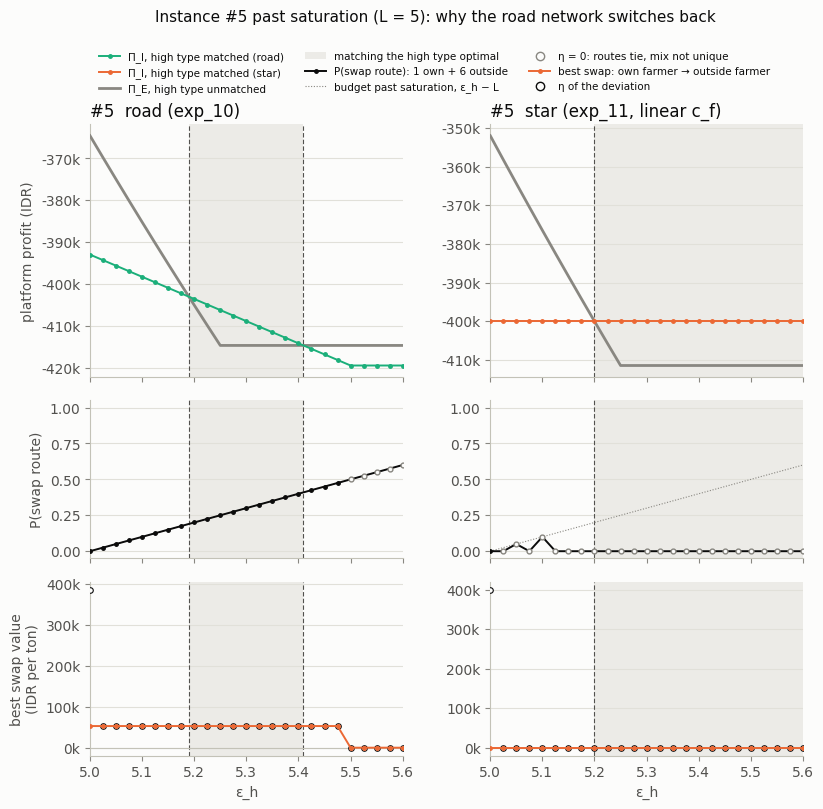

In [20]:
# Instance #5: the whole mechanism in one figure (road vs. star)
#   row 1: the race between keeping the high type matched (Π_I) and the efficient matching (Π_E)
#   row 2: the matched high type's worst-case deviation mixes in the swap route (one own farmer replaced by an outside one)
#   row 3: why: the value of the best one-for-one swap (own farmer out, outside farmer in) on the deviation's route,
#          with whole-route costs; it equals η, the value of one more ton of budget
I5, H5 = 5, "dreamy_hamilton"
OWN_COLOR, OUT_COLOR = "#184f95", "#eb6834"

fig, axes = plt.subplots(3, 2, figsize=(9.2, 8.2), sharex=True,
                         gridspec_kw={"height_ratios": [1.6, 1.0, 1.1], "hspace": 0.12, "wspace": 0.28})
for col, arm in enumerate(ARMS):
    w = wide.query("instance == @I5 and arm == @arm").sort_values("eps_h")
    eps = w["eps_h"].to_numpy()
    d = dev.query("instance == @I5 and arm == @arm and side == 'inefficient' and high_type == @H5").sort_values("eps_h")
    found = sorted(cross.query("instance == @I5 and arm == @arm")["crossing"].dropna())

    # shading where matching the high type is optimal, and where η = 0 (routes tie)
    bounds = [eps.min(), *found, eps.max()]
    for ax in axes[:, col]:
        for x0, x1 in zip(bounds[:-1], bounds[1:]):
            if np.interp((x0 + x1) / 2, eps, w["gap"].to_numpy()) > 0:
                ax.axvspan(x0, x1, color=SHADE, linewidth=0, zorder=0)
        for x in found:
            ax.axvline(x, color=INK_SECONDARY, linewidth=0.8, linestyle=(0, (4, 2)), zorder=1)
        ax.grid(axis="y")
        ax.set_axisbelow(True)

    # row 1: the race
    ax = axes[0, col]
    ax.plot(eps, w["Pi_E"], color=EFFICIENT_COLOR, linewidth=2, zorder=3, label="Π_E: high type unmatched")
    ax.plot(eps, w["Pi_I"], color=ARM_COLORS[arm], linewidth=1.4, marker="o", markersize=2.5, zorder=4,
            label="Π_I: high type matched")
    ax.set_title(f"#5  {'road (exp_10)' if arm == 'road' else 'star (exp_11, linear c_f)'}", loc="left", color=INK)
    ax.yaxis.set_major_formatter(thousands)

    # row 2: mixing probability on the swap route
    ax = axes[1, col]
    p_swap = []
    for r in d.itertuples():
        routes = sorted(r.routes, key=lambda rt: (rt["out"], -rt["own"]))
        p_swap.append(routes[-1]["weight"] if len(routes) > 1 and routes[-1]["out"] > routes[0]["out"] else 0.0)
    tie = d["eta"].abs().to_numpy() < 0.5
    ax.plot(d["eps_h"], p_swap, color=INK, linewidth=1.4, marker="o", markersize=2.5, zorder=4)
    ax.plot(d["eps_h"][tie], np.array(p_swap)[tie], "o", color=SURFACE, markeredgecolor=INK_MUTED, markersize=3.5, zorder=5)
    ax.plot(eps, np.clip(eps - L_of[I5], 0, None), color=INK_MUTED, linewidth=0.8, linestyle=(0, (1, 1.5)), zorder=2)
    ax.set_ylim(-0.05, 1.05)

    # row 3: why: the best one-for-one swap (own farmer out, outside farmer in) on the deviation's route, whole-route costs
    ax = axes[2, col]
    sw = swaps.query("instance == @I5 and arm == @arm and high_type == @H5").sort_values("eps_h")
    ax.axhline(0, color=AXIS, linewidth=0.8, zorder=1)
    ax.plot(sw["eps_h"], sw["best swap value"], color=OUT_COLOR, linewidth=1.4, marker="o", markersize=2.5, zorder=4)
    ax.plot(sw["eps_h"], sw["eta"], "o", color=SURFACE, markeredgecolor=INK, markersize=4, markeredgewidth=0.8, zorder=3)
    ax.yaxis.set_major_formatter(thousands)
    ax.set_xlabel("ε_h")
    ax.set_xlim(eps.min(), eps.max())

axes[0, 0].set_ylabel("platform profit (IDR)")
axes[1, 0].set_ylabel("P(swap route)")
axes[2, 0].set_ylabel("best swap value\n(IDR per ton)")
fig.legend(handles=[
    Line2D([], [], color=ARM_COLORS["road"], marker="o", markersize=2.5, linewidth=1.4, label="Π_I, high type matched (road)"),
    Line2D([], [], color=ARM_COLORS["star"], marker="o", markersize=2.5, linewidth=1.4, label="Π_I, high type matched (star)"),
    Line2D([], [], color=EFFICIENT_COLOR, linewidth=2, label="Π_E, high type unmatched"),
    Patch(facecolor=SHADE, label="matching the high type optimal"),
    Line2D([], [], color=INK, marker="o", markersize=2.5, linewidth=1.4, label="P(swap route): 1 own + 6 outside"),
    Line2D([], [], color=INK_MUTED, linewidth=0.8, linestyle=(0, (1, 1.5)), label="budget past saturation, ε_h − L"),
    Line2D([], [], marker="o", linestyle="none", color=SURFACE, markeredgecolor=INK_MUTED, label="η = 0: routes tie, mix not unique"),
    Line2D([], [], color=OUT_COLOR, marker="o", markersize=2.5, linewidth=1.4, label="best swap: own farmer → outside farmer"),
    Line2D([], [], marker="o", linestyle="none", color=SURFACE, markeredgecolor=INK, label="η of the deviation"),
], loc="lower center", bbox_to_anchor=(0.5, 0.905), ncol=3, fontsize=7.5)
fig.suptitle("Instance #5 past saturation (L = 5): why the road network switches back", fontsize=11, color=INK, y=1.02)
plt.savefig(FIG_DIR / "mechanism_5.png", bbox_inches="tight", dpi=300)
plt.show()
